# Segmentation sémantique des jardins urbains  ResNet34-UNet
## Dataset JARDINS 3 classes 6 bandes : R, G, B, NIR + NDVI + MSAVI2

**Architecture :** ResNet34-UNet (encodeur pré-entraîné ImageNet, décodeur UNet symétrique)  
**Capteur :** Orthophoto multi-spectrale 6 bandes pré-traitées (R, G, B, NIR, NDVI, MSAVI2)  
**Bandes d'entrée du modèle :** 6 canaux = R, G, B, NIR, NDVI, MSAVI2 — toutes lues directement depuis les fichiers source, aucun indice n'est calculé  
**Classes :** Non Jardins · Jardins familiaux · Jardins potagers · Jardins d'agrément  

| Section | Contenu |
|---------|---------|
| 0 | Installation des dépendances |
| 1 | Chargement du dataset |
| 2 | Imports |
| 3 | Configuration |
| 4 | Fonctions utilitaires |
| 5 | Patchification et chargement mémoire efficace |
| 6 | Répartition Train / Validation / Test |
| 7 | Distribution des classes + diagnostic potagers |
| 8 | Indices spectraux NDVI et MSAVI2 |
| 9 | Data Augmentation (potagers renforcés) |
| 10 | Architecture ResNet34-UNet |
| 11 | Fonctions de perte: Focal+Dice Loss + poids|
| 12 | Entraînement: AdamW + OneCycleLR + WeightedRandomSampler |
| 13 | Courbes d'apprentissage |
| 14 | Évaluation finale: calcul des métriques (TEST et VALIDATION) |
| 15 | Métriques globales (TEST): toutes classes |
| 16 | Focus sur les jardins (TEST): moyenne sur les 3 classes de jardins |
| 17 | Visualisation des prédictions |
| 17 | Sauvegarde du modèle |
| 18 | Inférence grande image : Tuilage + Soft-Voting + Hann |
| 19 | Références |


## 0. Installation des dépendances

In [ ]:
!pip install -q rasterio patchify psutil --no-deps patchify
!pip install -q albumentations scikit-learn
!pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu118


## 1. Chargement du dataset

Structure attendue après extraction :
```
DATASET_SPLIT/
├── Train/
│     ├── train aerial/img/   ← images  IMG_*.tif
│     └── train label/msk/    ← masques MSK_*.tif
├── val/
│     ├── valid aerial/img/
│     └── valid label/msk/
└── Test/
      ├── test aerial/img/
      └── test label/msk/
```


### Montage du Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


### Extraction de l'archive du dataset


In [ ]:
import zipfile, os

ZIP_PATH     = '/content/drive/MyDrive/DATA/DATASET_FINAL.zip'  # ← adapter
EXTRACT_DIR  = '/content/'
DATASET_ROOT = os.path.join(EXTRACT_DIR, 'DATASET_FINAL') # Corrected DATASET_ROOT

if not os.path.exists(DATASET_ROOT):
    print('Extraction du zip...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)
    print('Extraction terminée.')
else:
    print('Dataset déjà extrait.')

print('Contenu du dataset :')
for d in sorted(os.listdir(DATASET_ROOT)):
    print(f'  {d}')

Extraction du zip...
Extraction terminée.
Contenu du dataset :
  78 94
  91 77
  92 93 95


## 2. Imports

In [ ]:
import os, glob, random, copy, math, gc
import numpy as np
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from patchify import patchify
import psutil

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from torchvision import models

import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.metrics import (
    confusion_matrix, cohen_kappa_score,
    precision_score, recall_score, f1_score,
    classification_report
)
from collections import Counter

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Imports OK — device : {DEVICE}')


Imports OK — device : cuda


## 3. Configuration
Tous les hyperparamètres sont centralisés ici.  
Les principales mesures anti-overfitting (gel de l'encodeur, AdamW, CutMix, FocalDiceLoss, scheduler cosinus, dropout) sont commentées directement dans le code.


### Chemins des donnees, dimensions des patches et classes


In [ ]:
ALL_IMG_ROOTS = [
    os.path.join(DATASET_ROOT, '91 77',     'IMG'),
    os.path.join(DATASET_ROOT, '92 93 95',  'IMG'),
    os.path.join(DATASET_ROOT, '78 94',     'IMG'),
]
ALL_MSK_ROOTS = [
    os.path.join(DATASET_ROOT, '91 77',     'MSK'),
    os.path.join(DATASET_ROOT, '92 93 95',  'MSK'),
    os.path.join(DATASET_ROOT, '78 94',     'MSK'),
]

# ── Paramètres image ────────────────────────────────────────────────────────
IMAGE_PATCH_SIZE = 512
TILE_SIZE        = IMAGE_PATCH_SIZE

# Bandes lues directement depuis les fichiers .tif (déjà 6 canaux)
CHANNELS         = [0, 1, 2, 3, 4, 5] # R, G, B, NIR, NDVI, MSAVI2 (6 bandes)
NUM_BANDS_RAW    = len(CHANNELS)   # = 6  (bandes physiques)
NUM_BANDS        = 6               # = 6 bandes (plus de calcul)
IGNORE_INDEX     = -1

# ── Classes ──────────────────────────────────────────────────────────────────
CLASSES = [
    'Non Jardins',         # ID raster 1 → index Python 0
    'Jardins familiaux',   # ID raster 2 → index Python 1
    'Jardins potagers individuels',    # ID raster 3 → index Python 2
    "Jardins d'agrément",  # ID raster 4 → index Python 3
]
COLORS = [
    '#dc1010',   # Non Jardins: rouge foncé
    '#4defef',   # Jardins familiaux: gris-bleu pâle
    '#a86ee1',   # Jardins potagers:  violet
    '#79de13',   # Jardins d'agrément: orange
]
N_CLASSES   = len(CLASSES)
NUM_CLASSES = N_CLASSES

# ── Hyperparamètres entraînement ─────────────────────────────────────────────
EPOCHS              = 35
BATCH_SIZE          = 4
EARLY_STOP_PATIENCE = 10
MINORITY_AUG_COPIES = 0
MAX_GRAD_NORM       = 1.0

# ── Hyperparamètres optimiseur ───────────────────────────────────────────────
LR_MAX          = 1e-4
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.05

# ── Ratios du split ──────────────────────────────────────────────────────────
SPLIT_TRAIN = 0.70
SPLIT_TEST  = 0.20
SPLIT_VAL   = 0.10

# ── Vérification des chemins ─────────────────────────────────────────────────
for label, roots in [('IMG', ALL_IMG_ROOTS), ('MSK', ALL_MSK_ROOTS)]:
    for path in roots:
        status = 'OK' if os.path.exists(path) else 'CHEMIN INTROUVABLE !'
        print(f'{label}: {path}  [{status}]')

print(f'\nPatch size   : {IMAGE_PATCH_SIZE}px')
print(f'Bandes brutes: {CHANNELS}  ({NUM_BANDS_RAW} bandes → R, G, B, NIR, NDVI, MSAVI2)')
print(f'Bandes totales (entrée modèle) : {NUM_BANDS}  (toutes lues directement)')
print(f'Classes      : {N_CLASSES}: {CLASSES}')
print(f'Device       : {DEVICE}')
print(f'Split        : {int(SPLIT_TRAIN*100)}% train / {int(SPLIT_TEST*100)}% test / {int(SPLIT_VAL*100)}% val')
print()
print('Palette des classes :')
for i, (cls, col) in enumerate(zip(CLASSES, COLORS)):
    print(f'  [{i+1:2d}] {col}  {cls}')

IMG: /content/DATASET_FINAL/91 77/IMG  [OK]
IMG: /content/DATASET_FINAL/92 93 95/IMG  [OK]
IMG: /content/DATASET_FINAL/78 94/IMG  [OK]
MSK: /content/DATASET_FINAL/91 77/MSK  [OK]
MSK: /content/DATASET_FINAL/92 93 95/MSK  [OK]
MSK: /content/DATASET_FINAL/78 94/MSK  [OK]

Patch size   : 512px
Bandes brutes: [0, 1, 2, 3, 4, 5]  (6 bandes → R, G, B, NIR, NDVI, MSAVI2)
Bandes totales (entrée modèle) : 6  (toutes lues directement)
Classes      : 4: ['Non Jardins', 'Jardins familiaux', 'Jardins potagers individuels', "Jardins d'agrément"]
Device       : cuda
Split        : 70% train / 20% test / 10% val

Palette des classes :
  [ 1] #dc1010  Non Jardins
  [ 2] #4defef  Jardins familiaux
  [ 3] #a86ee1  Jardins potagers individuels
  [ 4] #79de13  Jardins d'agrément


### Hyperparametres d'entrainement, de perte et de normalisation


In [ ]:
# ══════════════════════════════════════════════════════════════════════════
# HYPERPARAMÈTRES — 6 bandes : R, G, B, NIR + NDVI + MSAVI2 (lecture directe)
# ══════════════════════════════════════════════════════════════════════════

# 1) Indices spectraux NDVI + MSAVI2 sont inclus dans les images sources.
#    Le calcul dynamique des indices spectraux est désactivé.

# 2) Rééquilibrage des classes rares : modéré et non cumulatif.
CLASS_WEIGHT_MAX    = 8.0    # plafond poids de classe
SAMPLER_MINORITY_W  = 3.0    # tirage patches potagers ×3 via WeightedRandomSampler
MINORITY_AUG_COPIES = 0      # désactivé : duplication redondante avec le sampler

# 3) Loss combinée Focal + Dice
FOCAL_WEIGHT = 0.5
DICE_WEIGHT  = 0.5
FOCAL_GAMMA  = 1.5

# 4) Learning rate différencié encodeur (pré-entraîné) / décodeur (neuf)
LR_ENCODER = 2e-5
LR_DECODER = 1e-4
WEIGHT_DECAY     = 1e-4
LABEL_SMOOTHING  = 0.05
EARLY_STOP_PATIENCE = 8

# 5) Normalisation percentile [2, 98]
NORM_PERCENTILES = (2, 98)

print('='*60)
print('  CONFIGURATION BANDES')
print('='*60)
print(f'  Bandes lues directement (.tif) : {CHANNELS}  → R, G, B, NIR, NDVI, MSAVI2')
print(f'  Indices calculés          : Aucun (bandes déjà présentes)')
print(f'  Total canaux entrée modèle: {NUM_BANDS}')
print('Hyperparamètres chargés.')

  CONFIGURATION BANDES
  Bandes lues directement (.tif) : [0, 1, 2, 3, 4, 5]  → R, G, B, NIR, NDVI, MSAVI2
  Indices calculés          : Aucun (bandes déjà présentes)
  Total canaux entrée modèle: 6
Hyperparamètres chargés.


## 4. Fonctions utilitaires

### Fonction collect_pairs: appariement des images et des masques


In [ ]:
def collect_pairs(img_root, msk_root):
    """Retourne la liste triée des paires (img_path, msk_path)."""
    img_files = sorted([
        os.path.join(img_root, f) for f in os.listdir(img_root)
        if f.lower().endswith(('.tif', '.tiff', '.jp2', '.png'))
    ])
    msk_files = sorted([
        os.path.join(msk_root, f) for f in os.listdir(msk_root)
        if f.lower().endswith(('.tif', '.tiff', '.jp2', '.png'))
    ])
    if len(img_files) != len(msk_files):
        raise ValueError(
            f'Nombre de fichiers différent : {len(img_files)} imgs vs {len(msk_files)} masques')
    return list(zip(img_files, msk_files))


### Fonction read_image -- lecture d'une image multi-bandes


In [ ]:
def read_image(path, channels):
    """Lit une image TIF multi-bandes → array float32 (H, W, C).

    Toutes les bandes spécifiées dans `channels` sont lues directement
    depuis le fichier .tif (ex: R,G,B,NIR,NDVI,MSAVI2).
    Aucun indice spectral n'est calculé dynamiquement.
    """
    with rasterio.open(path) as src:
        bands = [src.read(c + 1) for c in channels if c < src.count]
    return np.stack(bands, axis=-1).astype(np.float32)


### Fonction read_mask -- lecture et recodage d'un masque


In [ ]:
def read_mask(path, n_classes, ignore_index=IGNORE_INDEX):
    """
    Lit un masque TIF → array int64 (H, W), labels 0-indexed (0..n_classes-1).
    Les pixels hors plage [1, n_classes] reçoivent ignore_index.
    """
    with rasterio.open(path) as src:
        mask   = src.read(1).astype(np.int64)
        nodata = src.nodata
    out = np.full_like(mask, ignore_index)
    for cls in range(n_classes):
        out[mask == cls + 1] = cls
    if nodata is not None:
        out[mask == int(nodata)] = ignore_index
    return out


### Fonction normalize_image -- normalisation MinMax par canal


In [ ]:
def normalize_image(arr):
    """Normalisation MinMax canal par canal → [0, 1]."""
    arr = arr.astype(np.float32)
    for c in range(arr.shape[2]):
        band = arr[:, :, c]
        mn, mx = band.min(), band.max()
        arr[:, :, c] = (band - mn) / (mx - mn + 1e-8) if mx > mn else np.zeros_like(band)
    return arr


### Fonction mask_to_rgb -- conversion d'un masque en image couleur


In [ ]:
def mask_to_rgb(mask, colors=COLORS, ignore_index=IGNORE_INDEX):
    """Convertit un masque 0-indexed en image RGB. Pixels ignorés = noir."""
    rgb = np.zeros((*mask.shape, 3), dtype=np.uint8)
    for cls_id, hex_col in enumerate(colors):
        r = int(hex_col[1:3], 16)
        g = int(hex_col[3:5], 16)
        b = int(hex_col[5:7], 16)
        rgb[mask == cls_id] = [r, g, b]
    return rgb


### Fonction print_ram -- affichage de l'utilisation memoire


In [ ]:
def print_ram():
    vm = psutil.virtual_memory()
    print(f'  RAM système : {vm.used/1e9:.1f} / {vm.total/1e9:.1f} GB ({vm.percent:.0f}%)')
    if torch.cuda.is_available():
        alloc  = torch.cuda.memory_allocated() / 1e9
        reserv = torch.cuda.memory_reserved()  / 1e9
        print(f'  GPU         : {alloc:.2f} GB allouée / {reserv:.2f} GB réservée')


### Fonction diagnose_masks -- diagnostic des valeurs presentes dans les masques


In [ ]:
def diagnose_masks(msk_root, split_name, n_classes, max_files=None):
    msk_files = sorted(glob.glob(os.path.join(msk_root, 'MSK_*.tif')))
    if max_files:
        msk_files = msk_files[:max_files]
    print(f'\n=== Masques {split_name} ({len(msk_files)} fichiers) ===')
    if not msk_files:
        print(f'  [WARN] Aucun masque trouvé dans : {msk_root}')
        return
    all_vals = set()
    for p in msk_files:
        with rasterio.open(p) as src:
            m  = src.read(1)
            nd = src.nodata
        vals = np.unique(m)
        all_vals.update(vals.tolist())
        print(f'  {os.path.basename(p):40s} valeurs: {vals}  nodata={nd}  dtype={m.dtype}')
    expected = set(range(1, n_classes + 1))
    invalid  = all_vals - expected
    print(f'\n  Toutes valeurs vues : {sorted(all_vals)}')
    if invalid:
        print(f' Valeurs hors plage [1..{n_classes}] : {sorted(invalid)}'
              f' → seront ignorées (IGNORE_INDEX={IGNORE_INDEX})')
    else:
        print(f'  Toutes les valeurs sont dans la plage [1..{n_classes}]. OK')


### Fonction jaccard_score_batch -- calcul de l'IoU moyen sur un batch


In [ ]:
def jaccard_score_batch(logits, targets, n_classes, ignore_index=IGNORE_INDEX):
    """Calcule le score Jaccard (IoU) moyen pour un batch."""
    with torch.no_grad():
        preds = logits.argmax(dim=1)
        valid = (targets != ignore_index)
        if not valid.any():
            return 0.0
        intersection = torch.zeros(n_classes, dtype=torch.float32, device=logits.device)
        union        = torch.zeros(n_classes, dtype=torch.float32, device=logits.device)
        for cls in range(n_classes):
            pred_class   = (preds == cls) & valid
            target_class = (targets == cls) & valid
            intersection[cls] = (pred_class & target_class).sum().float()
            union[cls]        = (pred_class | target_class).sum().float()
        iou_per_class   = torch.where(union > 0, intersection / union,
                                      torch.tensor(0.0, device=logits.device))
        present_classes = targets[valid].unique()
        present_classes = present_classes[present_classes != ignore_index]
        if len(present_classes) == 0:
            return 0.0
        return iou_per_class[present_classes].mean().item()


## 5. Patchification et chargement mémoire efficace (mmap)
Les trois splits sont patchifiés une seule fois et sauvegardés sur disque.  
Le Dataset PyTorch lit directement depuis le fichier mmap (RAM ≈ 0).


### Creation du dossier de cache disque


In [ ]:
CACHE_DIR = '/content/patch_cache/'
os.makedirs(CACHE_DIR, exist_ok=True)
print(f'Dossier cache : {CACHE_DIR}')


Dossier cache : /content/patch_cache/


### Fonction build_all_mmap -- patchification et mise en cache mmap des donnees


In [ ]:
def build_all_mmap(img_roots, msk_roots, patch_size, channels, n_classes,
                   cache_dir, ignore_index=IGNORE_INDEX, force_rebuild=False):
    """
    Construit (ou charge depuis le cache) les patches numpy en mmap.

    Flux :
      1. Lire les 6 bandes (channels = [0,1,2,3,4,5] → R,G,B,NIR,NDVI,MSAVI2)
      2. Normaliser [0,1] canal par canal
         → tableau final (H, W, 6)
    """
    x_path = os.path.join(cache_dir, 'all_X.npy')
    y_path = os.path.join(cache_dir, 'all_y.npy')

    C = len(channels) # Should be 6

    if not force_rebuild and os.path.exists(x_path) and os.path.exists(y_path):
        print('  [ALL] Cache existant : chargement mmap...')
        X = np.load(x_path, mmap_mode='r')
        y = np.load(y_path, mmap_mode='r')
        # Vérification cohérence nombre de canaux
        if X.shape[3] != C:
            print(f'  [WARN] Cache existant a {X.shape[3]} canaux, attendu {C}.')
            print(f'         Lancez avec force_rebuild=True pour régénérer.')
        else:
            print(f'  [ALL] X={X.shape}  y={y.shape}')
        return X, y

    print('  [ALL] Construction du cache patches (tous dossiers)...')
    all_pairs = []
    for img_root, msk_root in zip(img_roots, msk_roots):
        all_pairs.extend(collect_pairs(img_root, msk_root))
    print(f'  [ALL] {len(all_pairs)} paires trouvées.')

    n_patches = 0
    for img_path, _ in all_pairs:
        with rasterio.open(img_path) as src:
            H, W = src.height, src.width
        H_c = (H // patch_size) * patch_size
        W_c = (W // patch_size) * patch_size
        if H_c > 0 and W_c > 0:
            n_patches += (H_c // patch_size) * (W_c // patch_size)
    if n_patches == 0:
        raise ValueError(f'Aucun patch extrait. Vérifiez IMAGE_PATCH_SIZE ({patch_size}).')

    print(f'  [ALL] {n_patches} patches × {patch_size}×{patch_size}×{C}')
    print(f'        Canaux : {channels} (toutes lues directement) = {C} canaux totaux')

    X_out = np.lib.format.open_memmap(
        x_path, mode='w+', dtype=np.float32,
        shape=(n_patches, patch_size, patch_size, C))
    y_out = np.lib.format.open_memmap(
        y_path, mode='w+', dtype=np.int64,
        shape=(n_patches, patch_size, patch_size))

    idx = 0
    for img_path, msk_path in all_pairs:
        # Étape 1 : lire les 6 bandes brutes → (H, W, 6)
        image = read_image(img_path, channels)
        # Étape 2 : normaliser [0, 1] canal par canal
        image = normalize_image(image)

        H, W, _ = image.shape
        H_c = (H // patch_size) * patch_size
        W_c = (W // patch_size) * patch_size
        if H_c == 0 or W_c == 0:
            print(f'    [SKIP] {os.path.basename(img_path)} trop petite.')
            continue
        image = image[:H_c, :W_c, :]
        mask  = read_mask(msk_path, n_classes, ignore_index)[:H_c, :W_c]
        p_img = patchify(image, (patch_size, patch_size, C), step=patch_size)
        p_msk = patchify(mask,  (patch_size, patch_size),    step=patch_size)
        for i in range(p_img.shape[0]):
            for j in range(p_img.shape[1]):
                X_out[idx] = p_img[i, j, 0]
                y_out[idx] = p_msk[i, j]
                idx += 1
        del image, mask, p_img, p_msk
        gc.collect()

    X_out.flush(); y_out.flush()
    X = np.load(x_path, mmap_mode='r')
    y = np.load(y_path, mmap_mode='r')
    print(f'  [ALL] Cache écrit. X={X.shape}  y={y.shape}')
    return X, y


### Fonction split_indices_stratified -- repartition stratifiee train / validation / test


In [ ]:
def split_indices_stratified(y_all, train_ratio, test_ratio, val_ratio,
                              n_classes, ignore_index=IGNORE_INDEX, seed=42):
    """
    Découpe les indices en train/test/val selon les ratios donnés,
    en préservant la distribution des classes (stratification par patch dominant).
    """
    assert abs(train_ratio + test_ratio + val_ratio - 1.0) < 1e-6, 'Les ratios doivent sommer à 1.0'
    rng = np.random.default_rng(seed)
    N   = len(y_all)
    dom_class = np.full(N, -1, dtype=np.int64)
    for i in range(N):
        m = np.array(y_all[i], dtype=np.int64).ravel()
        m = m[m != ignore_index]
        if m.size > 0:
            dom_class[i] = np.bincount(m, minlength=n_classes).argmax()
    train_idx, test_idx, val_idx = [], [], []
    for c in range(n_classes):
        idx_c = np.where(dom_class == c)[0]
        if idx_c.size == 0:
            continue
        idx_c = rng.permutation(idx_c)
        n     = len(idx_c)
        n_tr  = max(1, int(round(n * train_ratio)))
        n_te  = max(1, int(round(n * test_ratio)))
        n_va  = n - n_tr - n_te
        if n_va < 0:
            n_te += n_va; n_va = 0
        train_idx.extend(idx_c[:n_tr].tolist())
        test_idx.extend( idx_c[n_tr:n_tr+n_te].tolist())
        val_idx.extend(  idx_c[n_tr+n_te:].tolist())
    unassigned = np.where(dom_class == -1)[0]
    train_idx.extend(unassigned.tolist())
    return sorted(train_idx), sorted(test_idx), sorted(val_idx)


### Classe MmapSubset -- vue indexee en lecture seule sur un tableau mmap


In [ ]:
class MmapSubset:
    """Vue read-only d'un array mmap selon une liste d'indices."""
    def __init__(self, arr, indices):
        self._arr     = arr
        self._indices = indices
    def __len__(self):
        return len(self._indices)
    def __getitem__(self, i):
        return self._arr[self._indices[i]]


### Chargement des donnees en cache et construction des splits Train / Validation / Test


In [ ]:
print('RAM avant chargement :'); print_ram()

# FORCE_REBUILD_CACHE = True est obligatoire au 1er lancement pour s'assurer
# que le cache est généré avec les 6 bandes lues directement.
# Remettre à False pour les runs suivants (chargement rapide depuis le cache)
FORCE_REBUILD_CACHE = True

print('\n=== Chargement de TOUTES les données ===')
X_all, y_all = build_all_mmap(
    ALL_IMG_ROOTS, ALL_MSK_ROOTS,
    IMAGE_PATCH_SIZE, CHANNELS, N_CLASSES, CACHE_DIR,
    force_rebuild=FORCE_REBUILD_CACHE)

# Vérification : doit afficher 6 canaux
assert X_all.shape[3] == NUM_BANDS, (
    f'Erreur : cache a {X_all.shape[3]} canaux, attendu {NUM_BANDS}. '
    f'Relancez avec FORCE_REBUILD_CACHE = True.')

print('\n=== Split stratifié 70 / 20 / 10 ===')
train_idx, test_idx, val_idx = split_indices_stratified(
    y_all, SPLIT_TRAIN, SPLIT_TEST, SPLIT_VAL, N_CLASSES)

X_train = MmapSubset(X_all, train_idx)
y_train = MmapSubset(y_all, train_idx)
X_test  = MmapSubset(X_all, test_idx)
y_test  = MmapSubset(y_all, test_idx)
X_valid = MmapSubset(X_all, val_idx)
y_valid = MmapSubset(y_all, val_idx)

IMAGE_CHANNELS = X_all.shape[3]   # = 6
# NUM_BANDS est déjà fixé à 6 en section 3 — vérification cohérence
assert IMAGE_CHANNELS == NUM_BANDS, (
    f'IMAGE_CHANNELS={IMAGE_CHANNELS} ≠ NUM_BANDS={NUM_BANDS}')

print()
print('='*55)
print('  RÉSUMÉ DES BANDES EN CACHE')
print('='*55)
print(f'  Canal 0 : R   (bande lue directement)')
print(f'  Canal 1 : G   (bande lue directement)')
print(f'  Canal 2 : B   (bande lue directement)')
print(f'  Canal 3 : NIR (bande lue directement)')
print(f'  Canal 4 : NDVI  (bande lue directement)')
print(f'  Canal 5 : MSAVI2 (bande lue directement)')
print(f'  Total   : {IMAGE_CHANNELS} canaux')
print('='*55)
print(f'  Train : {len(X_train)} patches')
print(f'  Test  : {len(X_test)} patches')
print(f'  Val   : {len(X_valid)} patches')
print(f'\nRAM après chargement :'); print_ram()


RAM avant chargement :
  RAM système : 2.1 / 13.6 GB (18%)
  GPU         : 0.00 GB allouée / 0.00 GB réservée

=== Chargement de TOUTES les données ===
  [ALL] Construction du cache patches (tous dossiers)...
  [ALL] 3330 paires trouvées.
  [ALL] 3330 patches × 512×512×6
        Canaux : [0, 1, 2, 3, 4, 5] (toutes lues directement) = 6 canaux totaux
  [ALL] Cache écrit. X=(3330, 512, 512, 6)  y=(3330, 512, 512)

=== Split stratifié 70 / 20 / 10 ===

  RÉSUMÉ DES BANDES EN CACHE
  Canal 0 : R   (bande lue directement)
  Canal 1 : G   (bande lue directement)
  Canal 2 : B   (bande lue directement)
  Canal 3 : NIR (bande lue directement)
  Canal 4 : NDVI  (bande lue directement)
  Canal 5 : MSAVI2 (bande lue directement)
  Total   : 6 canaux
  Train : 2331 patches
  Test  : 665 patches
  Val   : 334 patches

RAM après chargement :
  RAM système : 1.9 / 13.6 GB (17%)
  GPU         : 0.00 GB allouée / 0.00 GB réservée


## 6. Répartition Train / Validation / Test

────────────────────────────────────────────────────────────
  RÉPARTITION DES DIVISIONS
────────────────────────────────────────────────────────────
  Division              Patches   Proportion
────────────────────────────────────────────────────────────
  Train                    2331        70.0%
  Validation                334        10.0%
  Test                      665        20.0%
────────────────────────────────────────────────────────────
  Total                    3330       100.0%


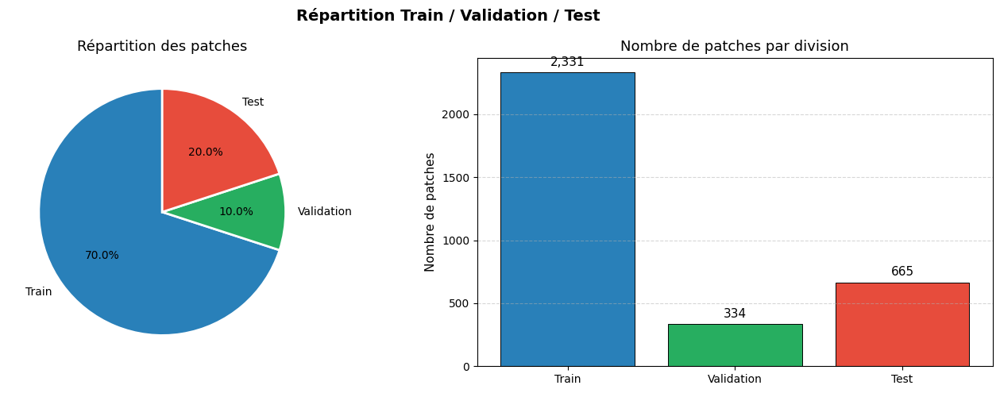

In [ ]:
total_patches = len(X_train) + len(X_valid) + len(X_test)
print(f'{"─"*60}')
print(f'  RÉPARTITION DES DIVISIONS')
print(f'{"─"*60}')
print(f'  {"Division":<20s} {"Patches":>8s} {"Proportion":>12s}')
print(f'{"─"*60}')
for name, X in [('Train', X_train), ('Validation', X_valid), ('Test', X_test)]:
    pct = 100 * len(X) / total_patches
    print(f'  {name:<20s} {len(X):>8d} {pct:>11.1f}%')
print(f'{"─"*60}')
print(f'  {"Total":<20s} {total_patches:>8d} {"100.0%":>12s}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
split_names  = ['Train', 'Validation', 'Test']
split_counts = [len(X_train), len(X_valid), len(X_test)]
split_colors = ['#2980B9', '#27AE60', '#E74C3C']

axes[0].pie(split_counts, labels=split_names, colors=split_colors,
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Répartition des patches', fontsize=13)

bars = axes[1].bar(split_names, split_counts, color=split_colors,
                   edgecolor='black', linewidth=0.7)
for bar, cnt in zip(bars, split_counts):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + total_patches * 0.01,
                 f'{cnt:,}', ha='center', va='bottom', fontsize=11)
axes[1].set_ylabel('Nombre de patches', fontsize=11)
axes[1].set_title('Nombre de patches par division', fontsize=13)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle('Répartition Train / Validation / Test', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('split_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Distribution des classes par split — Diagnostic automatique potagers

Ce diagnostic détecte automatiquement si la classe `Jardins potagers` est absente ou
sous-représentée dans le split train, ce qui causerait des métriques nulles à l'évaluation.



  Distribution — TRAIN (611,057,664 pixels valides)
  Classe                             Pixels   Fréq (%)
  ─────────────────────────────────────────────────────
  [1] Non Jardins                 489,627,042    80.128%  ||||||||||||||||||||||||||||||||||||||||
  [2] Jardins familiaux            73,228,061    11.984%  |||||
  [3] Jardins potagers individuels    3,096,701     0.507%  
  [4] Jardins d'agrément           45,105,860     7.382%  |||

  Distribution — VALIDATION (87,556,096 pixels valides)
  Classe                             Pixels   Fréq (%)
  ─────────────────────────────────────────────────────
  [1] Non Jardins                  70,258,563    80.244%  ||||||||||||||||||||||||||||||||||||||||
  [2] Jardins familiaux            10,855,060    12.398%  ||||||
  [3] Jardins potagers individuels      817,782     0.934%  
  [4] Jardins d'agrément            5,624,691     6.424%  |||

  Distribution — TEST (174,325,760 pixels valides)
  Classe                             Pixels

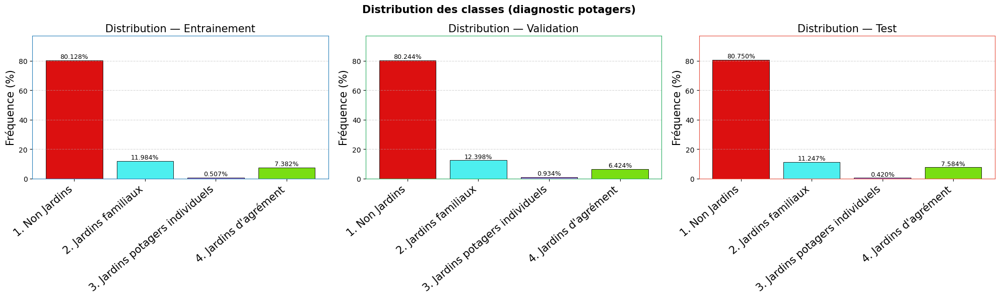

In [ ]:
def compute_class_distribution(y_data, n_classes, split_name, ignore_index=IGNORE_INDEX):
    counts = np.zeros(n_classes, dtype=np.float64)
    total  = 0
    for i in range(len(y_data)):
        chunk = y_data[i].ravel()
        chunk = chunk[chunk != ignore_index]
        for c in range(n_classes):
            counts[c] += (chunk == c).sum()
        total += chunk.size
        if i % 50 == 0:
            gc.collect()
    freqs = counts / (total + 1e-10) * 100
    print(f'\n  Distribution — {split_name} ({total:,} pixels valides)')
    print(f'  {"Classe":<28s} {"Pixels":>12s} {"Fréq (%)":>10s}')
    print('  ' + '─' * 53)
    for c in range(n_classes):
        bar = '|' * int(freqs[c] / 2)
        flag = '   ABSENT !' if counts[c] == 0 else ('   RARE (<0.5%)' if freqs[c] < 0.5 else '')
        print(f'  [{c+1}] {CLASSES[c]:<26s} {int(counts[c]):>12,} {freqs[c]:>9.3f}%  {bar}{flag}')
    return counts, freqs


counts_train, freqs_train = compute_class_distribution(y_train, N_CLASSES, 'TRAIN')
counts_valid, freqs_valid = compute_class_distribution(y_valid, N_CLASSES, 'VALIDATION')
counts_test,  freqs_test  = compute_class_distribution(y_test,  N_CLASSES, 'TEST')

# ── Diagnostic automatique classe potagers ───────────────────────
print('\n' + '='*65)
print('  DIAGNOSTIC JARDINS POTAGERS')
print('='*65)
POTAGER_IDX = 2  # index Python de Jardins potagers
for split_name, counts in [('TRAIN', counts_train), ('VAL', counts_valid), ('TEST', counts_test)]:
    n_pot = int(counts[POTAGER_IDX])
    total = int(counts.sum())
    pct   = 100 * n_pot / (total + 1e-10)
    status = 'ABSENT ' if n_pot == 0 else (f'RARE   ({pct:.4f}%)' if pct < 0.5 else f'OK ({pct:.2f}%)')
    print(f'  {split_name:<6s}: {n_pot:>12,} px potagers — {status}')

# Compter les patches contenant des potagers
train_potager_patches = sum(
    1 for i in range(len(y_train))
    if (np.array(y_train[i]) == POTAGER_IDX).any()
)
print(f'\n  Patches train contenant potagers : {train_potager_patches} / {len(y_train)}')
if train_potager_patches == 0:
    print('   CRITIQUE : aucun patch train avec potagers !')
    print('     → Le modèle ne peut pas apprendre cette classe.')
    print('     → Vérifiez vos masques (valeur raster=3 ?).')
elif train_potager_patches < 10:
    print('    ATTENTION : très peu de patches potagers — oversampling critique.')
else:
    print(f'   Patches suffisants — WeightedRandomSampler + copies x{MINORITY_AUG_COPIES} activés.')

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)
x = np.arange(N_CLASSES)
tick_labels = [f'{i+1}. {CLASSES[i]}' for i in range(N_CLASSES)]
for ax, (freqs, split_name, edge_col) in zip(
    axes,
    [(freqs_train, 'Entrainement', '#2980B9'),
     (freqs_valid, 'Validation', '#27AE60'),
     (freqs_test,  'Test', '#E74C3C')]
):
    bars = ax.bar(x, freqs, color=COLORS, edgecolor='black', linewidth=0.6)
    for bar, f in zip(bars, freqs):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f'{f:.3f}%', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(tick_labels, rotation=40, ha='right', fontsize=15)
    ax.set_ylabel('Fréquence (%)', fontsize=15)
    ax.set_title(f'Distribution — {split_name}', fontsize=15)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    for spine in ax.spines.values():
        spine.set_edgecolor(edge_col)
    ax.set_ylim(0, max(max(freqs_train), max(freqs_valid), max(freqs_test)) * 1.2)
plt.suptitle('Distribution des classes (diagnostic potagers)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('class_distribution.tiff', dpi=500, bbox_inches='tight')
plt.show()

## 8. Indices spectraux — Visualisation NDVI et MSAVI2
- **NDVI** = (NIR − R) / (NIR + R) — indice de végétation normalisé  
- **MSAVI2** = (2·NIR + 1 − √((2·NIR+1)² − 8·(NIR−R))) / 2 — correction fond de sol  

Les indices sont déjà intégrés dans les patches (canaux 4 et 5).  
Pour référence, ces formules utilisent NIR (canal 3) et R (canal 0) ; les indices eux-mêmes sont lus directement depuis les fichiers source, aucun calcul n'est effectué ici.  


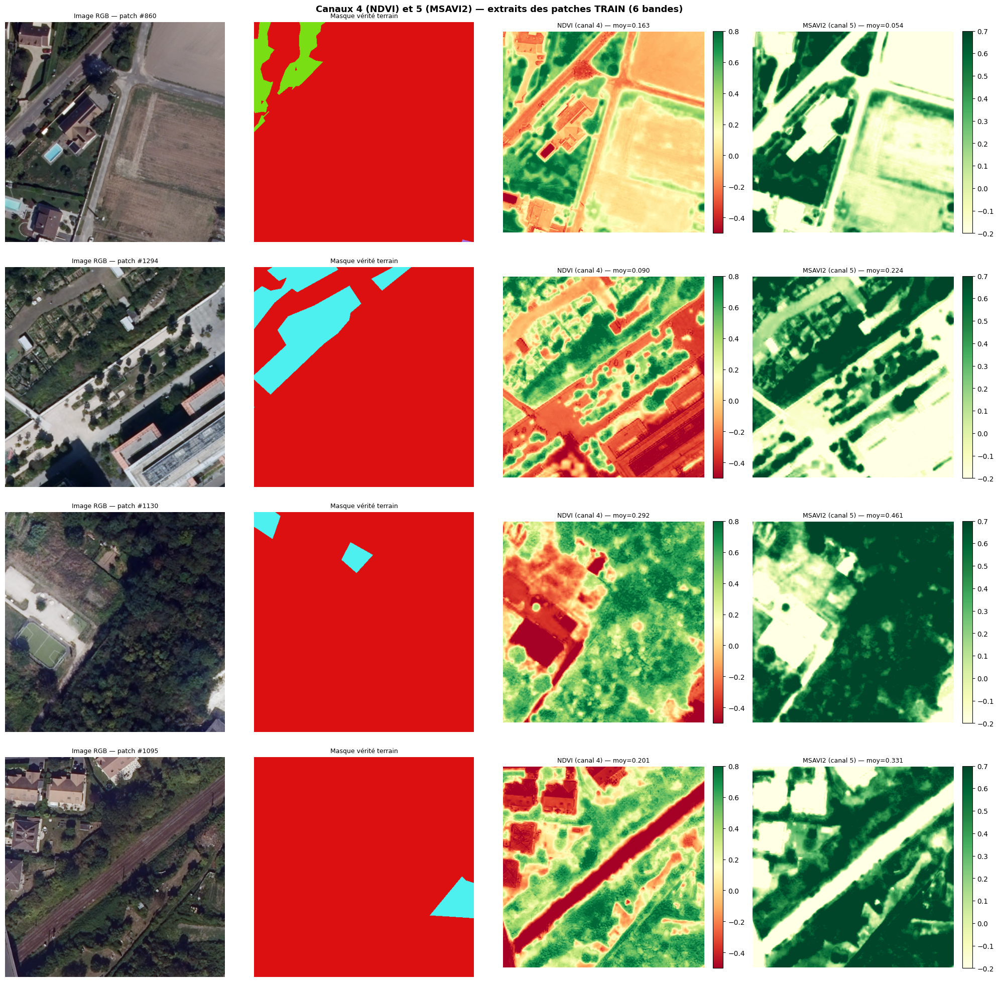

Figure sauvegardée → spectral_indices_ndvi_msavi.png

Statistiques des 6 canaux (sur 20 patches train) :
  Canal    Nom           Min      Max      Moy      Std
  ──────────────────────────────────────────────────
  [0]     R           0.000    1.000    0.356    0.191
  [1]     G           0.000    1.000    0.354    0.170
  [2]     B           0.000    1.000    0.345    0.157
  [3]     NIR         0.000    1.000    0.416    0.128
  [4]     NDVI        0.000    1.000    0.595    0.185
  [5]     MSAVI2      0.000    1.000    0.589    0.259


In [ ]:
# ── Visualisation des indices spectraux déjà calculés dans le cache ──────────
# Canal 4 = NDVI  (remappé [0,1])
# Canal 5 = MSAVI2 (remappé [0,1])
# Pour l'affichage, on reconvertit vers l'espace [-1,1] original

np.random.seed(42)
sample_indices = np.random.randint(0, len(X_train), size=4)
fig, axes = plt.subplots(4, 4, figsize=(20, 20))

for row, idx in enumerate(sample_indices):
    img  = np.array(X_train[idx], dtype=np.float32)   # (H, W, 6)
    mask = np.array(y_train[idx], dtype=np.int64)

    # NDVI et MSAVI2 sont en [0,1] dans le cache
    # Reconvertir vers [-1,1] pour l'affichage avec les bonnes échelles
    ndvi  = img[:, :, 4] * 2.0 - 1.0   # [0,1] → [-1,1]
    msavi = img[:, :, 5] * 2.0 - 1.0   # [0,1] → [-1,1]
    valid_px = mask != IGNORE_INDEX

    # Colonne 0 : image RGB (canaux 0,1,2)
    axes[row, 0].imshow(np.clip(img[:, :, :3], 0, 1))
    axes[row, 0].set_title(f'Image RGB — patch #{idx}', fontsize=9)
    axes[row, 0].axis('off')

    # Colonne 1 : masque vérité terrain
    axes[row, 1].imshow(mask_to_rgb(mask))
    axes[row, 1].set_title('Masque vérité terrain', fontsize=9)
    axes[row, 1].axis('off')

    # Colonne 2 : NDVI (canal 4)
    im2 = axes[row, 2].imshow(ndvi, cmap='RdYlGn', vmin=-0.5, vmax=0.8)
    axes[row, 2].set_title(
        f'NDVI (canal 4) — moy={ndvi[valid_px].mean():.3f}', fontsize=9)
    axes[row, 2].axis('off')
    plt.colorbar(im2, ax=axes[row, 2], fraction=0.046, pad=0.04)

    # Colonne 3 : MSAVI2 (canal 5)
    im3 = axes[row, 3].imshow(msavi, cmap='YlGn', vmin=-0.2, vmax=0.7)
    axes[row, 3].set_title(
        f'MSAVI2 (canal 5) — moy={msavi[valid_px].mean():.3f}', fontsize=9)
    axes[row, 3].axis('off')
    plt.colorbar(im3, ax=axes[row, 3], fraction=0.046, pad=0.04)

plt.suptitle(
    'Canaux 4 (NDVI) et 5 (MSAVI2) — extraits des patches TRAIN (6 bandes)',
    fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('spectral_indices_ndvi_msavi.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → spectral_indices_ndvi_msavi.png')

# ── Statistiques des 6 canaux sur un batch ────────────────────────────────
print('\nStatistiques des 6 canaux (sur 20 patches train) :')
canal_names = ['R', 'G', 'B', 'NIR', 'NDVI', 'MSAVI2']
print(f'  {"Canal":<8s} {"Nom":<8s} {"Min":>8s} {"Max":>8s} {"Moy":>8s} {"Std":>8s}')
print('  ' + '─'*50)
n_sample = min(20, len(X_train))
sample_stack = np.stack([np.array(X_train[i]) for i in range(n_sample)])  # (N,H,W,6)
for c, name in enumerate(canal_names):
    vals = sample_stack[:, :, :, c].ravel()
    print(f'  [{c}]     {name:<8s} {vals.min():>8.3f} {vals.max():>8.3f} '
          f'{vals.mean():>8.3f} {vals.std():>8.3f}')
del sample_stack


## 9. Data Augmentation



### Detection de la version d'Albumentations installee (compatibilite API)


In [ ]:
import albumentations as A
import albumentations
from packaging import version

ALB_VERSION = version.parse(albumentations.__version__)
ALB_NEW     = ALB_VERSION >= version.parse("2.0.0")
print(f'  Albumentations version : {albumentations.__version__}  →  API {"nouvelle (≥2.0)" if ALB_NEW else "ancienne (<2.0)"}')


  Albumentations version : 2.0.8  →  API nouvelle (≥2.0)


### Fonction make_gauss_noise -- bruit gaussien compatible anciennes/nouvelles API Albumentations


In [ ]:
def make_gauss_noise(std_low, std_high, p):
    """GaussNoise compatible ancienne et nouvelle API Albumentations."""
    if ALB_NEW:
        # API ≥ 2.0 : std_range
        return A.GaussNoise(std_range=(std_low, std_high), p=p)
    else:
        # API < 2.0 : var_limit (variance = std²)
        return A.GaussNoise(var_limit=(std_low**2, std_high**2), per_channel=True, p=p)


### Fonction make_elastic -- deformation elastique compatible anciennes/nouvelles API Albumentations


In [ ]:
def make_elastic(alpha, sigma, p):
    """ElasticTransform compatible ancienne et nouvelle API."""
    if ALB_NEW:
        return A.ElasticTransform(alpha=alpha, sigma=sigma, p=p)
    else:
        return A.ElasticTransform(alpha=alpha, sigma=sigma, alpha_affine=sigma * 0.1, p=p)


### Fonction make_coarse_dropout -- trous aleatoires compatibles anciennes/nouvelles API Albumentations


In [ ]:
def make_coarse_dropout(num_holes_range, hole_height_range, hole_width_range, p):
    """CoarseDropout compatible ancienne et nouvelle API."""
    if ALB_NEW:
        return A.CoarseDropout(
            num_holes_range=num_holes_range,
            hole_height_range=hole_height_range,
            hole_width_range=hole_width_range,
            p=p)
    else:
        # API < 2.0 : max_holes, min_holes, max_height, min_height, etc.
        return A.CoarseDropout(
            max_holes=num_holes_range[1],
            min_holes=num_holes_range[0],
            max_height=hole_height_range[1],
            min_height=hole_height_range[0],
            max_width=hole_width_range[1],
            min_width=hole_width_range[0],
            p=p)


### Pipelines d'augmentation -- general et specifique aux jardins potagers


In [ ]:
# ── Pipeline augmentation — général (tous patches) ───────────────────────
train_augment = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Transpose(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.RandomGamma(gamma_limit=(80, 120), p=0.4),
    make_gauss_noise(0.005, 0.03, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    make_coarse_dropout(
        num_holes_range=(1, 4),
        hole_height_range=(16, 64),
        hole_width_range=(16, 64),
        p=0.2),
], is_check_shapes=False)

# ── Pipeline augmentation spécifique Jardins potagers ─────────────
# Augmentation plus agressive : ElasticTransform + GridDistortion
# simule la variabilité de forme et de texture des potagers
potager_augment = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.75),
    A.Transpose(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=45, p=0.5),
    make_elastic(alpha=1, sigma=50, p=0.4),
    A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.6),
    A.RandomGamma(gamma_limit=(70, 130), p=0.5),
    make_gauss_noise(0.005, 0.04, p=0.4),
    A.GaussianBlur(blur_limit=(3, 7), p=0.3),
    make_coarse_dropout(
        num_holes_range=(1, 6),
        hole_height_range=(8, 32),
        hole_width_range=(8, 32),
        p=0.3),
], is_check_shapes=False)

MINORITY_CLASS_IDX = 2   # Jardins potagers


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


### Classe JardinsDataset -- Dataset PyTorch avec suréchantillonnage cible des jardins potagers


In [ ]:
class JardinsDataset(Dataset):
    """
    Les patches contenant des potagers reçoivent (avec proba 0.5) le pipeline
    'potager_augment' plus riche en déformations, sinon le pipeline général.
    La sur-représentation est assurée uniquement par le WeightedRandomSampler
    (modéré), pas par des copies physiques."""

    def __init__(self, X, y, augment=None, potager_augment=None,
                 minority_class=MINORITY_CLASS_IDX,
                 sampler_minority_w=SAMPLER_MINORITY_W):
        self.X, self.y = X, y
        self.augment = augment
        self.potager_augment = potager_augment
        self.minority_class = minority_class
        self.has_minority = []
        self.sample_weights = []
        for i in range(len(X)):
            hm = bool((np.array(y[i], dtype=np.int64) == minority_class).any())
            self.has_minority.append(hm)
            self.sample_weights.append(sampler_minority_w if hm else 1.0)
        if augment is not None:
            n_min = sum(self.has_minority)
            print(f'  [JardinsDataset] {n_min}/{len(X)} patches potagers '
                  f'(poids sampler x{sampler_minority_w}, 0 copie).')

    def __len__(self):
        return len(self.X)

    def get_sample_weights(self):
        return self.sample_weights

    def __getitem__(self, idx):
        image = np.array(self.X[idx], dtype=np.float32)
        mask = np.array(self.y[idx], dtype=np.int64)
        pipeline = None
        if self.augment is not None:
            if (self.has_minority[idx] and self.potager_augment is not None
                    and random.random() < 0.5):
                pipeline = self.potager_augment
            else:
                pipeline = self.augment
        if pipeline is not None:
            out = pipeline(image=image, mask=mask.astype('int32'))
            image = np.clip(out['image'], 0.0, 1.0)
            mask = out['mask'].astype('int64')
        img_t = torch.from_numpy(image.transpose(2, 0, 1))
        mask_t = torch.from_numpy(mask)
        return img_t, mask_t


### Fonction make_loaders -- construction des DataLoaders Train / Validation / Test


In [ ]:
def make_loaders(use_augmentation=True):
    if use_augmentation:
        train_ds = JardinsDataset(X_train, y_train, augment=train_augment,
                                  potager_augment=potager_augment)
        w = torch.tensor(train_ds.get_sample_weights(), dtype=torch.float)
        sampler = torch.utils.data.WeightedRandomSampler(
            weights=w, num_samples=len(w), replacement=True)
        tr = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                        num_workers=2, pin_memory=False,
                        prefetch_factor=2, persistent_workers=True)
    else:
        train_ds = JardinsDataset(X_train, y_train, augment=None)
        tr = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=2, pin_memory=False,
                        prefetch_factor=2, persistent_workers=True)
    vl = DataLoader(JardinsDataset(X_valid, y_valid, augment=None),
                    batch_size=BATCH_SIZE, shuffle=False,
                    num_workers=1, pin_memory=False, persistent_workers=True)
    te = DataLoader(JardinsDataset(X_test, y_test, augment=None),
                    batch_size=BATCH_SIZE, shuffle=False,
                    num_workers=1, pin_memory=False, persistent_workers=True)
    return tr, vl, te


### Verification des pipelines et visualisation d'un patch potager augmente


Pipeline augmentation général  : 9 transformations
Pipeline augmentation potagers : 12 transformations
Classe minoritaire ciblée      : 2 (Jardins potagers individuels)
Copies oversampling potagers   : 0



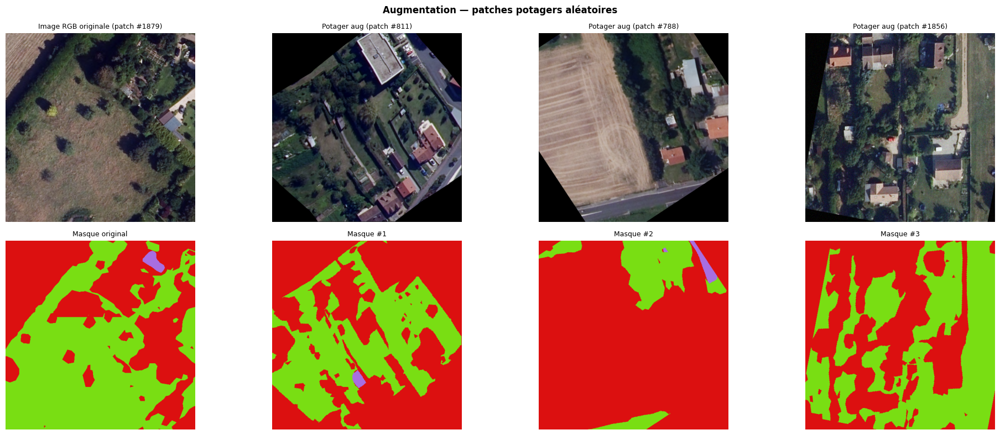

Figure sauvegardée → augmentation_potagers_random.png


In [ ]:
# ── Vérifications ─────────────────────────────────────────────────────────────
print(f'Pipeline augmentation général  : {len(train_augment.transforms)} transformations')
print(f'Pipeline augmentation potagers : {len(potager_augment.transforms)} transformations')
print(f'Classe minoritaire ciblée      : {MINORITY_CLASS_IDX} ({CLASSES[MINORITY_CLASS_IDX]})')
print(f'Copies oversampling potagers   : {MINORITY_AUG_COPIES}')
print()

# ── Vérification visuelle patch potager ──────────────────────────────────────
# Find an index for a patch containing the minority class, if available.
# Otherwise, pick a random patch.
minority_patches_indices = [i for i, has_minority in enumerate(JardinsDataset(X_train, y_train).has_minority) if has_minority]

# Ensure there's at least one patch to display; if not, pick a random one.
if not minority_patches_indices:
    print(' Aucun patch potager trouvé dans le train — vérifiez vos masques!')
    # Fallback to a random patch if no minority class patches are found
    minority_patches_indices = [random.randint(0, len(X_train) - 1)]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))

# Display original image and mask from a randomly selected minority patch
idx_orig = random.choice(minority_patches_indices)
rgb_orig = np.array(X_train[idx_orig], dtype=np.float32)[:, :, :3]
axes[0, 0].imshow(np.clip(rgb_orig, 0, 1))
axes[0, 0].set_title(f'Image RGB originale (patch #{idx_orig})', fontsize=9)
axes[1, 0].imshow(mask_to_rgb(y_train[idx_orig]))
axes[1, 0].set_title('Masque original', fontsize=9)

# Display random augmentations from other minority patches
for col in range(1, 4):
    # Pick a random patch that contains the minority class for augmentation
    idx_aug = random.choice(minority_patches_indices)

    ic  = np.array(X_train[idx_aug], dtype=np.float32)
    mc  = np.array(y_train[idx_aug], dtype=np.int32)

    aug_pipeline = potager_augment # Always use the more aggressive potager augmentation
    label        = 'Potager aug'

    out = aug_pipeline(image=ic, mask=mc)
    axes[0, col].imshow(np.clip(out['image'][:, :, :3], 0, 1))
    axes[0, col].set_title(f'{label} (patch #{idx_aug})', fontsize=9)
    axes[1, col].imshow(mask_to_rgb(out['mask'].astype('int64')))
    axes[1, col].set_title(f'Masque #{col}', fontsize=9)
    del ic, mc, out
    gc.collect()

for ax in axes.flat:
    ax.axis('off')
plt.suptitle(f'Augmentation — patches potagers aléatoires', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('augmentation_potagers_random.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → augmentation_potagers_random.png')

## 10. Architecture ResNet34-UNet — Dropout

### Classe ConvBnRelu -- bloc convolution + BatchNorm + ReLU


In [ ]:
class ConvBnRelu(nn.Module):
    """Convolution 3×3 + BatchNorm + ReLU."""
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size,
                      padding=padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


### Classe DecoderBlock -- bloc decodeur UNet (upsampling + fusion skip connection)


In [ ]:
class DecoderBlock(nn.Module):
    """Bloc décodeur UNet : Upsample + concat skip + ConvBnRelu×2 + Dropout2d."""
    def __init__(self, in_channels, skip_channels, out_channels, dropout_p=0.0):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv1    = ConvBnRelu(in_channels + skip_channels, out_channels)
        self.dropout  = nn.Dropout2d(p=dropout_p) if dropout_p > 0.0 else nn.Identity()
        self.conv2    = ConvBnRelu(out_channels, out_channels)

    def forward(self, x, skip=None):
        x = self.upsample(x)
        if skip is not None:
            if x.shape != skip.shape:
                x = F.pad(x, [0, skip.shape[3] - x.shape[3],
                               0, skip.shape[2] - x.shape[2]])
            x = torch.cat([x, skip], dim=1)
        x = self.conv1(x)
        x = self.dropout(x)
        x = self.conv2(x)
        return x


### Classe ResNet34UNet -- encodeur ResNet34 pre-entraine + decodeur UNet


In [ ]:
class ResNet34UNet(nn.Module):
    """
    Encodeur ResNet34 pré-entraîné (ImageNet) + décodeur UNet symétrique.
    Suppression du bottleneck : e4 → decoder4 directement (comme figure UNet standard).
    """
    def __init__(self, num_classes=N_CLASSES, in_channels=NUM_BANDS, pretrained=True):
        super().__init__()
        encoder = models.resnet34(weights='IMAGENET1K_V1' if pretrained else None)

        original_conv1 = encoder.conv1
        new_conv1 = nn.Conv2d(in_channels, 64, kernel_size=7,
                               stride=2, padding=3, bias=False)
        if pretrained and in_channels >= 3:
            new_conv1.weight.data[:, :3] = original_conv1.weight.data
            for b in range(3, in_channels):
                new_conv1.weight.data[:, b] = original_conv1.weight.data.mean(dim=1)
        elif pretrained:
            new_conv1.weight.data = original_conv1.weight.data
        encoder.conv1 = new_conv1

        self.encoder_stem   = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.encoder_pool   = encoder.maxpool
        self.encoder_layer1 = encoder.layer1   # 64 ch
        self.encoder_layer2 = encoder.layer2   # 128 ch
        self.encoder_layer3 = encoder.layer3   # 256 ch
        self.encoder_layer4 = encoder.layer4   # 512 ch

        # ── Plus de bottleneck — e4 → decoder4 directement ──────────────────

        self.decoder4 = DecoderBlock(512, 256, 256, dropout_p=0.4)
        self.decoder3 = DecoderBlock(256, 128, 128, dropout_p=0.3)
        self.decoder2 = DecoderBlock(128,  64,  64, dropout_p=0.2)
        self.decoder1 = DecoderBlock( 64,  64,  64, dropout_p=0.1)
        self.decoder0 = DecoderBlock( 64,   0,  32, dropout_p=0.1)

        self.segmentation_head = nn.Sequential(
            ConvBnRelu(32, 32),
            nn.Dropout2d(0.2),
            nn.Conv2d(32, num_classes, kernel_size=1)
        )

    def forward(self, x):
        e0 = self.encoder_stem(x)
        e1 = self.encoder_layer1(self.encoder_pool(e0))
        e2 = self.encoder_layer2(e1)
        e3 = torch.utils.checkpoint.checkpoint(
            self.encoder_layer3, e2, use_reentrant=False)
        e4 = torch.utils.checkpoint.checkpoint(
            self.encoder_layer4, e3, use_reentrant=False)

        # e4 directement dans le décodeur, pas de bottleneck
        d4 = self.decoder4(e4, skip=e3)
        d3 = self.decoder3(d4, skip=e2)
        d2 = self.decoder2(d3, skip=e1)
        d1 = self.decoder1(d2, skip=e0)
        d0 = self.decoder0(d1, skip=None)
        return self.segmentation_head(d0)


### Fonction build_model -- instanciation du modele et comptage des parametres


In [ ]:
def build_model(num_classes=N_CLASSES, in_channels=NUM_BANDS, pretrained=True):
    m = ResNet34UNet(num_classes=num_classes,
                     in_channels=in_channels,
                     pretrained=pretrained).to(DEVICE)
    n_params = sum(p.numel() for p in m.parameters())
    n_train  = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'  ResNet34-UNet sur {DEVICE}')
    print(f'  Paramètres totaux       : {n_params:,}')
    print(f'  Paramètres entraînables : {n_train:,}')
    return m


### Verification de l'architecture sur un batch factice


In [ ]:
print('Vérification de l\'architecture...')
_test_model = build_model(pretrained=False)
_dummy      = torch.zeros(1, NUM_BANDS, IMAGE_PATCH_SIZE, IMAGE_PATCH_SIZE).to(DEVICE)
with torch.no_grad():
    _out = _test_model(_dummy)
print(f'  Entrée : {tuple(_dummy.shape)}')
print(f'  Sortie : {tuple(_out.shape)}')
assert _out.shape == (1, N_CLASSES, IMAGE_PATCH_SIZE, IMAGE_PATCH_SIZE)
del _test_model, _dummy, _out
gc.collect()
print('Architecture validée.')


Vérification de l'architecture...
  ResNet34-UNet sur cuda
  Paramètres totaux       : 24,540,484
  Paramètres entraînables : 24,540,484
  Entrée : (1, 6, 512, 512)
  Sortie : (1, 4, 512, 512)
Architecture validée.


## 11. Fonctions de perte — Focal + Dice Loss + poids median-frequency



### Import complementaire pour les fonctions de perte


In [ ]:
import torch.nn.functional as F


### Fonction calculate_median_frequency_weights -- poids de classes par frequence mediane inverse


In [ ]:
def calculate_median_frequency_weights(y_data, n_classes, ignore_index=IGNORE_INDEX):
    class_counts = np.zeros(n_classes, dtype=np.int64)
    total_pixels = np.int64(0)
    for i in range(len(y_data)):
        mask = np.array(y_data[i], dtype=np.int64).ravel()
        mask = mask[mask != ignore_index]
        if mask.size == 0: continue
        unique, counts = np.unique(mask, return_counts=True)
        for u, c in zip(unique, counts):
            if u < n_classes: # Ensure class index is within bounds
                class_counts[u] += c
        total_pixels += mask.size

    class_freq = class_counts / (total_pixels + 1e-10)
    median_freq = np.median(class_freq[class_freq > 0]) # Exclude zero-frequency classes from median

    # Calculate class weights using inverse median frequency smoothing
    # Apply smoothing to avoid infinite weights for absent classes, or use 0 weight instead
    class_weights_raw = median_freq / (class_freq + 1e-10) # Add epsilon to avoid division by zero
    class_weights_raw[class_freq == 0] = 0.0 # Assign 0 weight to completely absent classes

    # Normalize weights to avoid extremely large values, up to a ceiling
    class_weights = np.clip(class_weights_raw, 0, CLASS_WEIGHT_MAX)

    # Convert to torch tensor
    return torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)


### Classe FocalDiceLoss -- perte combinee Focal Loss + Dice Loss


In [ ]:
class FocalDiceLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2, ignore_index=-1, reduction='mean',
                 label_smoothing=0.0, n_classes=4, focal_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.alpha = alpha if alpha is not None else torch.ones(n_classes)
        self.gamma = gamma
        self.ignore_index = ignore_index
        self.reduction = reduction
        self.label_smoothing = label_smoothing
        self.n_classes = n_classes
        self.focal_weight = focal_weight
        self.dice_weight = dice_weight

    def focal_loss(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none',
                                  ignore_index=self.ignore_index,
                                  weight=self.alpha)
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma * ce_loss).mean()
        return focal_loss

    def dice_loss(self, inputs, targets):
        num_labels = self.n_classes
        true_one_hot = F.one_hot(targets.long(), num_labels)
        true_one_hot = true_one_hot.permute(0, 3, 1, 2).float()

        # Apply label smoothing to true_one_hot
        if self.label_smoothing > 0:
            true_one_hot = true_one_hot * (1 - self.label_smoothing) + self.label_smoothing / num_labels

        probas = F.softmax(inputs, dim=1)

        # Handle ignore_index: set probabilities and true_one_hot to 0 for ignored pixels
        valid_mask = (targets != self.ignore_index).unsqueeze(1).float()
        probas = probas * valid_mask
        true_one_hot = true_one_hot * valid_mask

        dims = (0,) + tuple(range(2, inputs.ndim)) # Sum over batch and spatial dimensions

        intersection = torch.sum(probas * true_one_hot, dims)
        cardinality = torch.sum(probas + true_one_hot, dims)

        dice = (2. * intersection) / (cardinality + 1e-8)
        return (1 - dice).mean() # Mean over classes

    def forward(self, inputs, targets):
        f_loss = self.focal_loss(inputs, targets)
        d_loss = self.dice_loss(inputs, targets)
        return self.focal_weight * f_loss + self.dice_weight * d_loss


### Calcul des poids de classe utilises par la fonction de perte


In [ ]:
# Calculate class weights for FocalDiceLoss
print('Calcul des poids de classe pour FocalDiceLoss...')
class_weights = calculate_median_frequency_weights(y_train, N_CLASSES, IGNORE_INDEX)
print(f'Poids de classe : {class_weights.cpu().numpy()}')


Calcul des poids de classe pour FocalDiceLoss...
Poids de classe : [0.12084088 0.8079821  8.         1.3117355 ]


## 12. Entraînement — AdamW + OneCycleLR + WeightedRandomSampler




### Fonction free_memory -- liberation de la memoire RAM et GPU


In [ ]:
def free_memory(*objects):
    for obj in objects:
        try:
            del obj
        except Exception:
            pass
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
        alloc  = torch.cuda.memory_allocated() / 1e9
        reserv = torch.cuda.memory_reserved()  / 1e9
        print(f'  GPU après nettoyage : {alloc:.2f} GB allouée / {reserv:.2f} GB réservée')


### Fonction run_epoch -- boucle d'entrainement ou d'evaluation sur une epoch


In [ ]:
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, train=True):
    """
    Exécute une epoch complète.
     scheduler.step() appelé APRÈS CHAQUE BATCH (OneCycleLR).
    """
    model.train() if train else model.eval()
    total_loss = total_correct = total_pixels = total_iou = 0.0
    processed  = 0

    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for imgs, masks in loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            if not (masks != IGNORE_INDEX).any():
                del imgs, masks
                continue
            if train:
                optimizer.zero_grad(set_to_none=True)
            logits = model(imgs)
            loss   = criterion(logits, masks)
            if torch.isnan(loss):
                del imgs, masks, logits, loss
                continue
            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()   # appelé par batch, pas par epoch (OneCycleLR)
            with torch.no_grad():
                preds = logits.argmax(dim=1)
                valid = masks != IGNORE_INDEX
                total_correct += ((preds == masks) & valid).sum().item()
                total_pixels  += valid.sum().item()
                total_iou     += jaccard_score_batch(logits, masks, N_CLASSES)
            total_loss += loss.item()
            processed  += 1
            del imgs, masks, logits, loss, preds, valid

    if processed == 0:
        return 0.0, 0.0, 0.0
    return (total_loss / processed,
            total_correct / max(total_pixels, 1),
            total_iou / processed)


### Fonction train_model -- entrainement complet avec early stopping


In [ ]:
def train_model(use_augmentation, label):
    print(f'\n{"="*65}\n  Entraînement — {label.upper().replace("_"," ")}\n{"="*65}')
    best_path = f'best_{label}.pth'
    mdl = build_model(num_classes=N_CLASSES, in_channels=NUM_BANDS, pretrained=True)
    crit = FocalDiceLoss(alpha=class_weights, gamma=FOCAL_GAMMA,
                         ignore_index=IGNORE_INDEX, label_smoothing=LABEL_SMOOTHING,
                         n_classes=N_CLASSES, focal_weight=FOCAL_WEIGHT, dice_weight=DICE_WEIGHT)
    tr_loader, vl_loader, _ = make_loaders(use_augmentation)

    # LR différencié : encodeur pré-entraîné (bas) vs décodeur neuf (haut)
    enc_params = [p for n, p in mdl.named_parameters() if n.startswith('encoder')]
    dec_params = [p for n, p in mdl.named_parameters() if not n.startswith('encoder')]
    opt = optim.AdamW([
        {'params': enc_params, 'lr': LR_ENCODER},
        {'params': dec_params, 'lr': LR_DECODER},
    ], weight_decay=WEIGHT_DECAY)

    total_steps = len(tr_loader) * EPOCHS
    sch = optim.lr_scheduler.OneCycleLR(
        opt, max_lr=[LR_ENCODER, LR_DECODER], total_steps=total_steps,
        pct_start=0.1, anneal_strategy='cos', div_factor=10.0, final_div_factor=100.0)

    hist = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': [],
            'jaccard': [], 'val_jaccard': [], 'lr': []}
    best_iou, patience = -1.0, 0
    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc, tr_iou = run_epoch(mdl, tr_loader, crit, opt, scheduler=sch, train=True)
        vl_loss, vl_acc, vl_iou = run_epoch(mdl, vl_loader, crit, None, scheduler=None, train=False)
        current_lr = opt.param_groups[1]['lr']  # LR décodeur
        for k, v in [('loss', tr_loss), ('val_loss', vl_loss), ('accuracy', tr_acc),
                     ('val_accuracy', vl_acc), ('jaccard', tr_iou), ('val_jaccard', vl_iou),
                     ('lr', current_lr)]:
            hist[k].append(v)
        tag = ''
        if vl_iou > best_iou:
            best_iou, patience = vl_iou, 0
            torch.save(mdl.state_dict(), best_path); tag = '  <- meilleur'
        else:
            patience += 1
        # Surapprentissage = ÉCART train/val DANS le même run (pas entre 2 runs)
        gap = tr_iou - vl_iou
        flag = '  [OVERFIT?]' if gap > 0.15 else ''
        print(f'Epoch {epoch:3d}/{EPOCHS} | Loss {tr_loss:.4f}/{vl_loss:.4f} | '
              f'Acc {tr_acc:.4f}/{vl_acc:.4f} | IoU {tr_iou:.4f}/{vl_iou:.4f} '
              f'(gap={gap:+.3f}{flag}) | LR {current_lr:.2e}{tag}')
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
        if patience >= EARLY_STOP_PATIENCE:
            print(f'  Early stopping epoch {epoch}.'); break
    print(f'\n  Meilleure val IoU : {best_iou:.4f} -> {best_path}')
    free_memory(mdl, crit, opt, sch, tr_loader, vl_loader)
    return hist, best_path


### Confirmation de la definition de train_model


In [ ]:
print('train_model défini.')


train_model défini.


### Run 1 — sans augmentation (référence)

In [ ]:

print('>>> Run 1/2 : sans augmentation')
history_no_aug, path_no_aug = train_model(use_augmentation=False, label='sans_aug')
print('\nNettoyage mémoire...')
free_memory()

>>> Run 1/2 : sans augmentation

  Entraînement — SANS AUG
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:06<00:00, 13.6MB/s]


  ResNet34-UNet sur cuda
  Paramètres totaux       : 24,540,484
  Paramètres entraînables : 24,540,484
Epoch   1/35 | Loss 0.5181/0.4829 | Acc 0.4872/0.5977 | IoU 0.2100/0.3399 (gap=-0.130) | LR 2.70e-05  <- meilleur
Epoch   2/35 | Loss 0.4603/0.4540 | Acc 0.5882/0.5854 | IoU 0.3044/0.3543 (gap=-0.050) | LR 6.51e-05  <- meilleur
Epoch   3/35 | Loss 0.4246/0.4351 | Acc 0.6549/0.6394 | IoU 0.3620/0.3875 (gap=-0.025) | LR 9.56e-05  <- meilleur
Epoch   4/35 | Loss 0.4014/0.4077 | Acc 0.6879/0.6697 | IoU 0.3930/0.4245 (gap=-0.031) | LR 9.99e-05  <- meilleur
Epoch   5/35 | Loss 0.3774/0.4033 | Acc 0.7420/0.7569 | IoU 0.4435/0.4771 (gap=-0.034) | LR 9.94e-05  <- meilleur
Epoch   6/35 | Loss 0.3502/0.4269 | Acc 0.7741/0.7425 | IoU 0.4796/0.4744 (gap=+0.005) | LR 9.85e-05
Epoch   7/35 | Loss 0.3368/0.4319 | Acc 0.8013/0.7262 | IoU 0.5154/0.4756 (gap=+0.040) | LR 9.70e-05
Epoch   8/35 | Loss 0.3189/0.4550 | Acc 0.8302/0.8102 | IoU 0.5491/0.5182 (gap=+0.031) | LR 9.50e-05  <- meilleur
Epoch   9/3

### Run 2 — avec augmentation (avec rééquilibrage des classes)

In [ ]:
print('>>> Run 2/2 : avec augmentation + WeightedRandomSampler')
history_aug, path_aug = train_model(use_augmentation=True, label='avec_aug')


>>> Run 2/2 : avec augmentation + WeightedRandomSampler

  Entraînement — AVEC AUG
  ResNet34-UNet sur cuda
  Paramètres totaux       : 24,540,484
  Paramètres entraînables : 24,540,484
  [JardinsDataset] 583/2331 patches potagers (poids sampler x3.0, 0 copie).
Epoch   1/35 | Loss 0.5669/0.5288 | Acc 0.1588/0.3998 | IoU 0.0751/0.2174 (gap=-0.142) | LR 2.70e-05  <- meilleur
Epoch   2/35 | Loss 0.5137/0.4517 | Acc 0.4169/0.6287 | IoU 0.1949/0.3742 (gap=-0.179) | LR 6.51e-05  <- meilleur
Epoch   3/35 | Loss 0.4731/0.4308 | Acc 0.5449/0.5986 | IoU 0.2757/0.3872 (gap=-0.112) | LR 9.56e-05  <- meilleur
Epoch   4/35 | Loss 0.4580/0.4088 | Acc 0.5870/0.6885 | IoU 0.3035/0.4388 (gap=-0.135) | LR 9.99e-05  <- meilleur
Epoch   5/35 | Loss 0.4331/0.4045 | Acc 0.6346/0.6914 | IoU 0.3305/0.4408 (gap=-0.110) | LR 9.94e-05  <- meilleur
Epoch   6/35 | Loss 0.4241/0.4022 | Acc 0.6530/0.7380 | IoU 0.3418/0.4620 (gap=-0.120) | LR 9.85e-05  <- meilleur
Epoch   7/35 | Loss 0.4170/0.3981 | Acc 0.6766/0.7389 

### Chargement du meilleur modele entraine (avec augmentation)


In [ ]:
# ── Chargement du meilleur modèle ────────────────────────────────────────────
print('Chargement du meilleur modèle (avec augmentation)...')
model = build_model(num_classes=N_CLASSES, in_channels=NUM_BANDS, pretrained=False)
model.load_state_dict(torch.load(path_aug, map_location=DEVICE))
model.eval()
print('Modèle prêt.')


Chargement du meilleur modèle (avec augmentation)...
  ResNet34-UNet sur cuda
  Paramètres totaux       : 24,540,484
  Paramètres entraînables : 24,540,484
Modèle prêt.


### Remarque -- rechargement redondant desactive


In [ ]:
# Le meilleur modèle (avec augmentation) est déjà chargé dans `model`
# par la cellule précédente. On NE recharge rien ici : on supprime simplement
# l'ancien code bogué qui faisait torch.load(MODEL_PATH) trop tôt.
print('Modèle prêt (déjà chargé depuis path_aug). Rien à recharger.')


Modèle prêt (déjà chargé depuis path_aug). Rien à recharger.


## 13. Courbes d'apprentissage

### Courbes d'apprentissage combinees -- comparaison sans aug vs avec aug


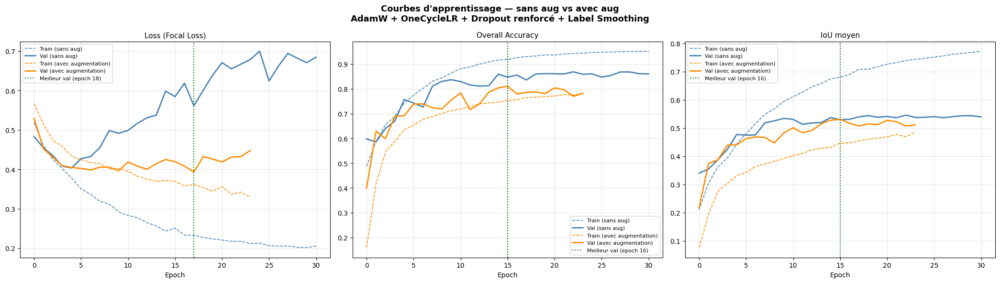

Figure sauvegardée → learning_curves.png


In [ ]:
metrics_plot = [
    ('loss',     'Loss (Focal Loss)', 'min'),
    ('accuracy', 'Overall Accuracy',  'max'),
    ('jaccard',  'IoU moyen',         'max'),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for ax, (key, title, direction) in zip(axes, metrics_plot):
    ax.plot(history_no_aug[key],          color='steelblue',  linestyle='--',
            label='Train (sans aug)', linewidth=1.2)
    ax.plot(history_no_aug[f'val_{key}'], color='steelblue',  linestyle='-',
            linewidth=2, label='Val (sans aug)')
    ax.plot(history_aug[key],             color='darkorange', linestyle='--',
            label='Train (avec augmentation)', linewidth=1.2)
    ax.plot(history_aug[f'val_{key}'],    color='darkorange', linestyle='-',
            linewidth=2, label='Val (avec augmentation)')

    best_val = history_aug[f'val_{key}']
    best_ep  = (np.argmin(best_val) if direction == 'min' else np.argmax(best_val))
    ax.axvline(best_ep, color='green', linestyle=':', linewidth=1.5,
               label=f'Meilleur val (epoch {best_ep+1})')

    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Epoch', fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Courbes d\'apprentissage — sans aug vs avec aug\n'
             'AdamW + OneCycleLR + Dropout renforcé + Label Smoothing',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → learning_curves.png')




### Courbes d'apprentissage separees -- sans augmentation puis avec augmentation


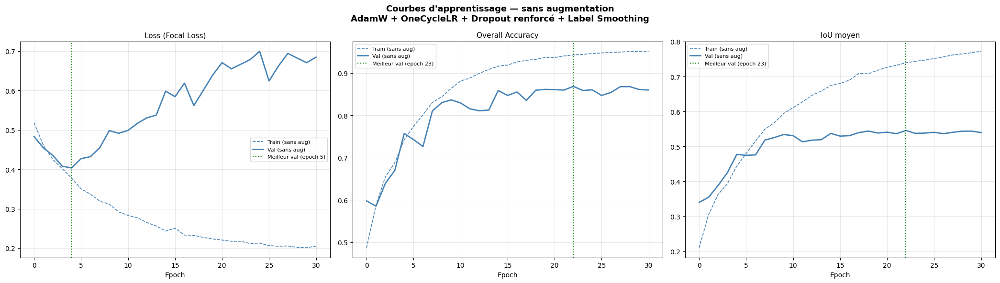

Figure sauvegardée → learning_curves_sans_aug.png


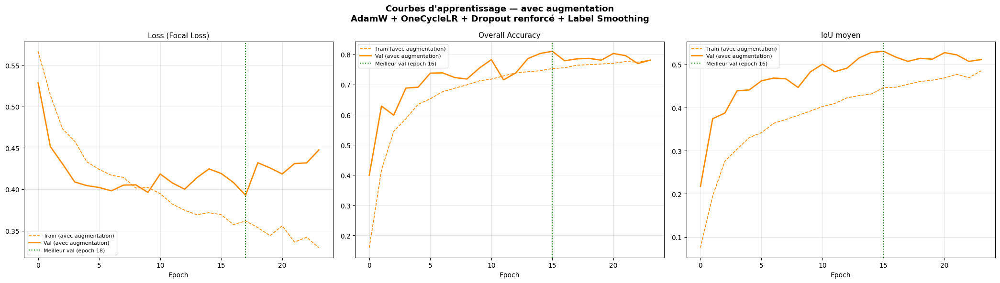

Figure sauvegardée → learning_curves_avec_aug.png


In [ ]:
metrics_plot = [
    ('loss',     'Loss (Focal Loss)', 'min'),
    ('accuracy', 'Overall Accuracy',  'max'),
    ('jaccard',  'IoU moyen',         'max'),
]

# --- Plot for "sans augmentation" ---
fig_no_aug, axes_no_aug = plt.subplots(1, 3, figsize=(21, 6))

for ax, (key, title, direction) in zip(axes_no_aug, metrics_plot):
    ax.plot(history_no_aug[key],          color='steelblue',  linestyle='--', label='Train (sans aug)', linewidth=1.2)
    ax.plot(history_no_aug[f'val_{key}'], color='steelblue',  linestyle='-',  label='Val (sans aug)',   linewidth=2)

    best_val_no_aug = history_no_aug[f'val_{key}']
    best_ep_no_aug  = (np.argmin(best_val_no_aug) if direction == 'min' else np.argmax(best_val_no_aug))
    ax.axvline(best_ep_no_aug, color='green', linestyle=':', linewidth=1.5,
               label=f'Meilleur val (epoch {best_ep_no_aug+1})')

    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Epoch', fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Courbes d\'apprentissage — sans augmentation\n' +\
             'AdamW + OneCycleLR + Dropout renforcé + Label Smoothing',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('learning_curves_sans_aug.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → learning_curves_sans_aug.png')

# --- Plot for "avec augmentation" ---
fig_aug, axes_aug = plt.subplots(1, 3, figsize=(21, 6))

for ax, (key, title, direction) in zip(axes_aug, metrics_plot):
    ax.plot(history_aug[key],             color='darkorange', linestyle='--', label='Train (avec augmentation)', linewidth=1.2)
    ax.plot(history_aug[f'val_{key}'],    color='darkorange', linestyle='-',  label='Val (avec augmentation)',   linewidth=2)

    best_val_aug = history_aug[f'val_{key}']
    best_ep_aug  = (np.argmin(best_val_aug) if direction == 'min' else np.argmax(best_val_aug))
    ax.axvline(best_ep_aug, color='green', linestyle=':', linewidth=1.5,
               label=f'Meilleur val (epoch {best_ep_aug+1})')

    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Epoch', fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('Courbes d\'apprentissage — avec augmentation\n' +\
             'AdamW + OneCycleLR + Dropout renforcé + Label Smoothing',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('learning_curves_avec_aug.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → learning_curves_avec_aug.png')


## 14. Évaluation finale — calcul des métriques (TEST et VALIDATION)

In [ ]:
def compute_all_metrics(mdl, X_data, y_data, n_classes, split_name,
                        ignore_index=IGNORE_INDEX):
    """
    Évalue le modèle sur un split.
    Version économe en RAM : les prédictions sont accumulées par batch
    sous forme de comptages (tp/fp/fn) sans jamais stocker tous les pixels.
    Seule la matrice de confusion (n_classes × n_classes) est gardée en RAM.
    """
    mdl.eval()
    loader = DataLoader(JardinsDataset(X_data, y_data, augment=None),
                        batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=1, pin_memory=False)

    # Compteurs cumulatifs — aucun tableau de pixels en mémoire
    tp = np.zeros(n_classes, dtype=np.int64)
    fp = np.zeros(n_classes, dtype=np.int64)
    fn = np.zeros(n_classes, dtype=np.int64)
    total_correct = np.int64(0)
    total_valid   = np.int64(0)
    cm_raw        = np.zeros((n_classes, n_classes), dtype=np.int64)

    with torch.no_grad():
        for imgs, masks in loader:
            imgs     = imgs.to(DEVICE)
            logits   = mdl(imgs)
            preds    = logits.argmax(dim=1).cpu().numpy().astype(np.int64)
            masks_np = masks.numpy().astype(np.int64)
            del imgs, logits

            valid = masks_np != ignore_index
            p_v   = preds[valid]
            t_v   = masks_np[valid]

            total_correct += int((p_v == t_v).sum())
            total_valid   += int(valid.sum())

            for cls in range(n_classes):
                tp[cls] += int(((p_v == cls) & (t_v == cls)).sum())
                fp[cls] += int(((p_v == cls) & (t_v != cls)).sum())
                fn[cls] += int(((p_v != cls) & (t_v == cls)).sum())

            # Matrice de confusion par batch (mémoire constante)
            for t in range(n_classes):
                mask_t = t_v == t
                if not mask_t.any():
                    continue
                for p in range(n_classes):
                    cm_raw[t, p] += int(((p_v == p) & mask_t).sum())

            del preds, masks_np, valid, p_v, t_v
            gc.collect()

    oa    = float(total_correct) / max(float(total_valid), 1.0)
    iou_per_class, dice_per_class = [], []
    precision_per_class, recall_per_class = [], []

    for cls in range(n_classes):
        union    = int(tp[cls]) + int(fp[cls]) + int(fn[cls])
        dice_den = 2 * int(tp[cls]) + int(fp[cls]) + int(fn[cls])
        prec_den = int(tp[cls]) + int(fp[cls])
        rec_den  = int(tp[cls]) + int(fn[cls])
        iou_per_class.append(tp[cls] / union if union > 0 else 0.0)
        dice_per_class.append(2 * tp[cls] / dice_den if dice_den > 0 else 0.0)
        precision_per_class.append(tp[cls] / prec_den if prec_den > 0 else 0.0)
        recall_per_class.append(tp[cls] / rec_den if rec_den > 0 else 0.0)

    miou      = float(np.mean(iou_per_class))
    mean_dice = float(np.mean(dice_per_class))

    present_classes = [c for c in range(n_classes) if cm_raw[c].sum() + cm_raw[:, c].sum() > 0]
    cm_sub  = cm_raw[np.ix_(present_classes, present_classes)]
    cm_norm = cm_sub.astype('float') / (cm_sub.sum(axis=1, keepdims=True) + 1e-8)

    # Kappa — calculé depuis la matrice de confusion (sans stocker tous les pixels)
    n_total = cm_raw.sum()
    if n_total > 0:
        p_o  = np.diag(cm_raw).sum() / n_total
        p_e  = ((cm_raw.sum(axis=1) / n_total) * (cm_raw.sum(axis=0) / n_total)).sum()
        kappa = float((p_o - p_e) / (1.0 - p_e + 1e-10))
    else:
        kappa = 0.0

    kappa_label = (
        'Presque parfait (> 0.80)' if kappa > 0.80 else
        'Fort (0.60 – 0.80)'       if kappa > 0.60 else
        'Modéré (0.40 – 0.60)'     if kappa > 0.40 else
        'Faible (< 0.40)'
    )

    print(f'\n{"="*65}')
    print(f'  MÉTRIQUES — {split_name}')
    print(f'{"="*65}')
    print(f'  Overall Accuracy (OA) : {oa:.4f}  ({oa*100:.2f} %)')
    print(f'  Kappa de Cohen        : {kappa:.4f}  — {kappa_label}')
    print(f'  mIoU (Jaccard moyen)  : {miou:.4f}')
    print(f'  Dice moyen (F1 moyen) : {mean_dice:.4f}')
    print()
    print(f'  {"Classe":<28s} {"Précision":>11s} {"Rappel":>9s} '
          f'{"F1/Dice":>9s} {"IoU":>9s}')
    print('  ' + '─' * 70)
    for i in range(n_classes):
        print(f'  [{i+1}] {CLASSES[i]:<26s} '
              f'{precision_per_class[i]:>11.4f} '
              f'{recall_per_class[i]:>9.4f} '
              f'{dice_per_class[i]:>9.4f} '
              f'{iou_per_class[i]:>9.4f}')

    return {
        'oa': oa, 'kappa': kappa, 'miou': miou, 'mean_dice': mean_dice,
        'iou': iou_per_class, 'dice': dice_per_class,
        'precision': precision_per_class, 'recall': recall_per_class,
        'cm_norm': cm_norm, 'cm_raw': cm_raw,
        'present_classes': present_classes,
    }


metrics_test = compute_all_metrics(model, X_test,  y_test,  N_CLASSES, 'TEST')
metrics_val  = compute_all_metrics(model, X_valid, y_valid, N_CLASSES, 'VALIDATION')
oa          = metrics_test['oa']
kappa       = metrics_test['kappa']
miou        = metrics_test['miou']
iou_per_cls = metrics_test['iou']



  MÉTRIQUES — TEST
  Overall Accuracy (OA) : 0.8254  (82.54 %)
  Kappa de Cohen        : 0.5613  — Modéré (0.40 – 0.60)
  mIoU (Jaccard moyen)  : 0.4680
  Dice moyen (F1 moyen) : 0.5925

  Classe                         Précision    Rappel   F1/Dice       IoU
  ──────────────────────────────────────────────────────────────────────
  [1] Non Jardins                     0.9535    0.8435    0.8951    0.8102
  [2] Jardins familiaux               0.7459    0.7833    0.7641    0.6183
  [3] Jardins potagers individuels      0.1692    0.4321    0.2432    0.1384
  [4] Jardins d'agrément              0.3468    0.7173    0.4675    0.3051

  MÉTRIQUES — VALIDATION
  Overall Accuracy (OA) : 0.8106  (81.06 %)
  Kappa de Cohen        : 0.5502  — Modéré (0.40 – 0.60)
  mIoU (Jaccard moyen)  : 0.4662
  Dice moyen (F1 moyen) : 0.5941

  Classe                         Précision    Rappel   F1/Dice       IoU
  ──────────────────────────────────────────────────────────────────────
  [1] Non Jardins       

## 15. Métriques globales (set TEST)

Les métriques de cette section sont calculées sur les 4 classes (Non Jardins et les trois types de jardins). Elles donnent une vue d'ensemble de la performance du modèle avant de se concentrer uniquement sur les jardins en section 16.

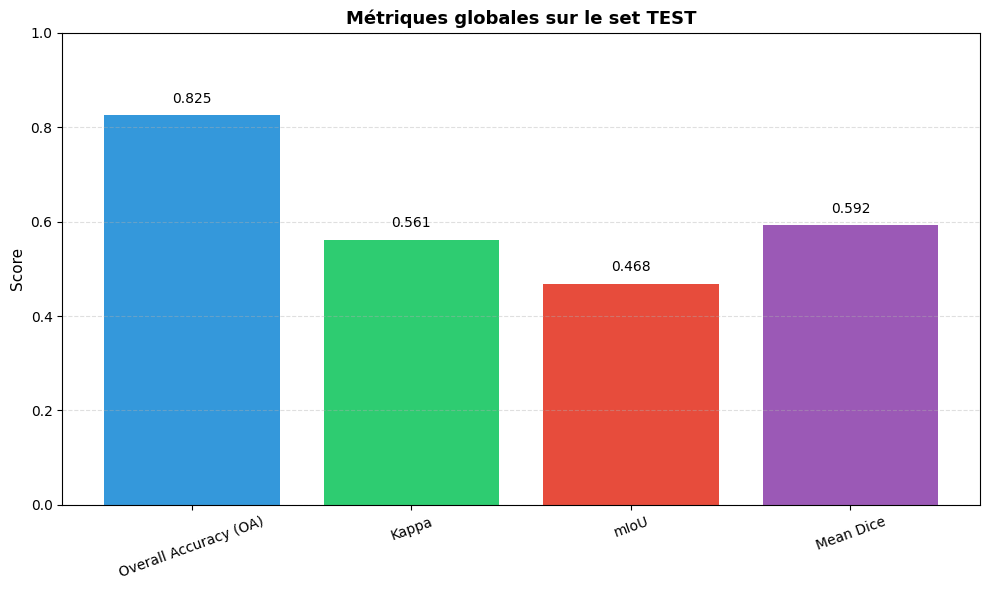

Figure sauvegardée → overall_metrics_test.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Overall metrics
overall_metrics_names = ['Overall Accuracy (OA)', 'Kappa', 'mIoU', 'Mean Dice']
overall_metrics_values = [metrics_test['oa'], metrics_test['kappa'], metrics_test['miou'], metrics_test['mean_dice']]

fig_overall, ax_overall = plt.subplots(figsize=(10, 6))
bars_overall = ax_overall.bar(overall_metrics_names, overall_metrics_values, color=['#3498DB', '#2ECC71', '#E74C3C', '#9B59B6'])

ax_overall.set_ylim(0, 1.0)
ax_overall.set_ylabel('Score', fontsize=11)
ax_overall.set_title('Métriques globales sur le set TEST', fontsize=13, fontweight='bold')
ax_overall.tick_params(axis='x', rotation=20, labelsize=10)
ax_overall.grid(axis='y', linestyle='--', alpha=0.4)

for bar in bars_overall:
    yval = bar.get_height()
    ax_overall.text(bar.get_x() + bar.get_width()/2, yval + 0.02, round(yval, 3), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('overall_metrics_test.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → overall_metrics_test.png')

### Matrice de confusion (toutes classes)

### Matrice de confusion normalisee (proportions par ligne)


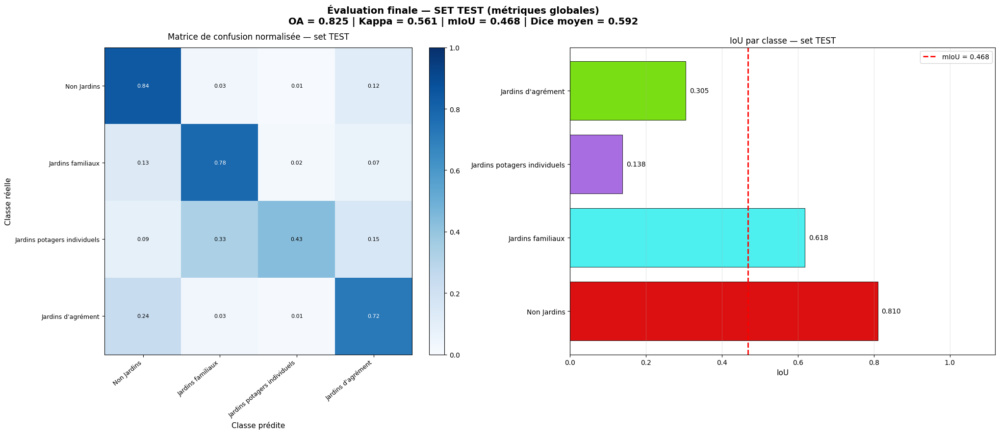

Figure sauvegardée → confusion_matrix_test.png


In [ ]:
class_labels = [CLASSES[c] for c in metrics_test['present_classes']]
cm_norm      = metrics_test['cm_norm']

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

im0 = axes[0].imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
axes[0].set_title('Matrice de confusion normalisée — set TEST', fontsize=12, pad=12)
axes[0].set_xlabel('Classe prédite', fontsize=11)
axes[0].set_ylabel('Classe réelle',  fontsize=11)
axes[0].set_xticks(range(len(class_labels)))
axes[0].set_yticks(range(len(class_labels)))
axes[0].set_xticklabels(class_labels, rotation=40, ha='right', fontsize=9)
axes[0].set_yticklabels(class_labels, fontsize=9)
for i in range(len(class_labels)):
    for j in range(len(class_labels)):
        val   = cm_norm[i, j]
        color = 'white' if val > 0.5 else 'black'
        axes[0].text(j, i, f'{val:.2f}', ha='center', va='center',
                     fontsize=8, color=color)
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

colors_bar = [COLORS[c] if c < len(COLORS) else '#888888'
              for c in metrics_test['present_classes']]
axes[1].barh(class_labels, iou_per_cls, color=colors_bar,
             edgecolor='black', linewidth=0.6)
axes[1].axvline(miou, color='red', linestyle='--', linewidth=2.0,
                label=f'mIoU = {miou:.3f}')
for i, v in enumerate(iou_per_cls):
    axes[1].text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=10)
axes[1].set_title('IoU par classe — set TEST', fontsize=12)
axes[1].set_xlabel('IoU', fontsize=11)
axes[1].set_xlim(0, 1.12)
axes[1].legend(fontsize=10)
axes[1].grid(axis='x', alpha=0.3)

plt.suptitle(
    f'Évaluation finale — SET TEST (métriques globales)\n'
    f'OA = {oa:.3f} | Kappa = {kappa:.3f} | mIoU = {miou:.3f} | '
    f'Dice moyen = {metrics_test["mean_dice"]:.3f}',
    fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix_test.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → confusion_matrix_test.png')


### Matrice de confusion brute (nombre de pixels)


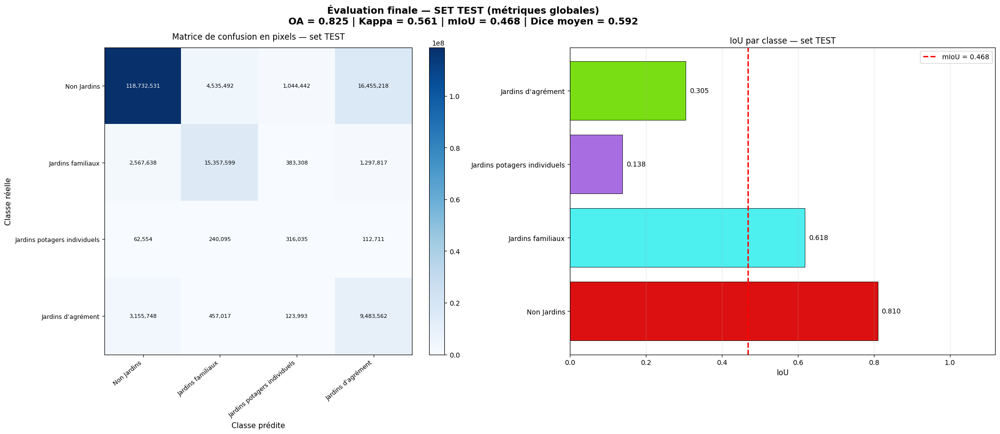

Figure sauvegardée → confusion_matrix_pixels_test.png


In [ ]:
class_labels = [CLASSES[c] for c in metrics_test['present_classes']]
cm_raw       = metrics_test['cm_raw']

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

# Dynamically determine vmax for better visualization of raw counts
max_pixel_count = cm_raw.max() if cm_raw.size > 0 else 1
im0 = axes[0].imshow(cm_raw, interpolation='nearest', cmap='Blues', vmin=0, vmax=max_pixel_count)
axes[0].set_title('Matrice de confusion en pixels — set TEST', fontsize=12, pad=12)
axes[0].set_xlabel('Classe prédite', fontsize=11)
axes[0].set_ylabel('Classe réelle',  fontsize=11)
axes[0].set_xticks(range(len(class_labels)))
axes[0].set_yticks(range(len(class_labels)))
axes[0].set_xticklabels(class_labels, rotation=40, ha='right', fontsize=9)
axes[0].set_yticklabels(class_labels, fontsize=9)
for i in range(len(class_labels)):
    for j in range(len(class_labels)):
        val   = cm_raw[i, j]
        # Adjust text color based on background darkness (heuristics for 'Blues' cmap)
        # Use white for darker blues (higher values), black for lighter blues (lower values)
        color = 'white' if val > (max_pixel_count / 2) else 'black'
        axes[0].text(j, i, f'{val:,.0f}', ha='center', va='center',  # Format as integer with comma
                     fontsize=8, color=color)
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

colors_bar = [COLORS[c] if c < len(COLORS) else '#888888'
              for c in metrics_test['present_classes']]
axes[1].barh(class_labels, iou_per_cls, color=colors_bar,
             edgecolor='black', linewidth=0.6)
axes[1].axvline(miou, color='red', linestyle='--', linewidth=2.0,
                label=f'mIoU = {miou:.3f}')
for i, v in enumerate(iou_per_cls):
    axes[1].text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=10)
axes[1].set_title('IoU par classe — set TEST', fontsize=12)
axes[1].set_xlabel('IoU', fontsize=11)
axes[1].set_xlim(0, 1.12)
axes[1].legend(fontsize=10)
axes[1].grid(axis='x', alpha=0.3)

plt.suptitle(
    f'Évaluation finale — SET TEST (métriques globales)\n'
    f'OA = {oa:.3f} | Kappa = {kappa:.3f} | mIoU = {miou:.3f} | '
    f'Dice moyen = {metrics_test["mean_dice"]:.3f}',
    fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix_pixels_test.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → confusion_matrix_pixels_test.png')

### Courbes ROC one-vs-rest (toutes classes)

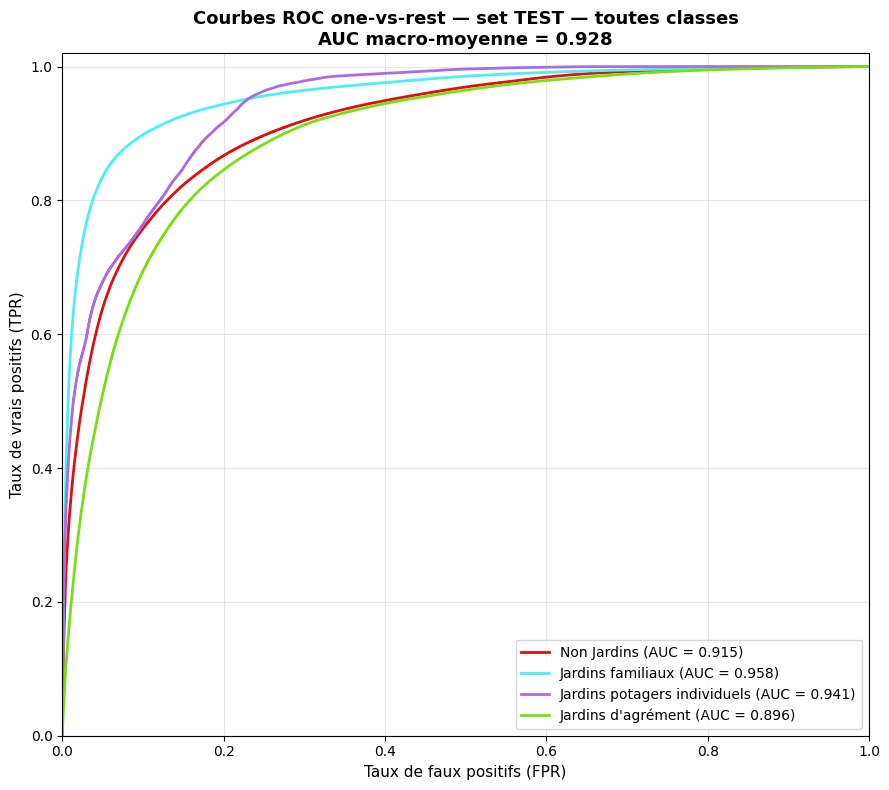

AUC par classe : Non Jardins=0.915, Jardins familiaux=0.958, Jardins potagers individuels=0.941, Jardins d'agrément=0.896
AUC macro (4 classes) = 0.928
Figure sauvegardée : roc_curves_test_global.png


In [ ]:
from sklearn.metrics import roc_curve, auc

def compute_roc_data(mdl, X_data, y_data, n_classes, ignore_index=IGNORE_INDEX,
                     max_per_class=300_000, seed=0):
    """ROC one-vs-rest, mémoire bornée par réservoir sous-échantillonné."""
    mdl.eval()
    rng = np.random.default_rng(seed)
    loader = DataLoader(JardinsDataset(X_data, y_data, augment=None),
                        batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=1, pin_memory=False)
    res = {c: {'s': [], 'y': []} for c in range(n_classes)}
    with torch.no_grad():
        for imgs, masks in loader:
            imgs = imgs.to(DEVICE)
            probs = torch.softmax(mdl(imgs), dim=1).cpu().numpy()  # (B,C,H,W)
            t = masks.numpy()
            del imgs
            p = probs.transpose(0, 2, 3, 1).reshape(-1, n_classes)
            t = t.reshape(-1)
            valid = t != ignore_index
            p, t = p[valid], t[valid]
            for c in range(n_classes):
                s = p[:, c]; lab = (t == c).astype(np.uint8)
                if len(s) > max_per_class:
                    sel = rng.choice(len(s), max_per_class, replace=False)
                    s, lab = s[sel], lab[sel]
                res[c]['s'].append(s.astype(np.float32)); res[c]['y'].append(lab)
            gc.collect()
    roc = {}
    for c in range(n_classes):
        s = np.concatenate(res[c]['s']); y = np.concatenate(res[c]['y'])
        if 0 < y.sum() < len(y):
            fpr, tpr, _ = roc_curve(y, s)
            roc[c] = (fpr, tpr, auc(fpr, tpr))
    return roc


roc_test = compute_roc_data(model, X_test, y_test, N_CLASSES)

plt.figure(figsize=(9, 8))
aucs_global = []
for c, (fpr, tpr, a) in sorted(roc_test.items()):
    aucs_global.append(a)
    plt.plot(fpr, tpr, color=COLORS[c] if c < len(COLORS) else None, linewidth=2,
             label=f'{CLASSES[c]} (AUC = {a:.3f})')

macro_auc_global = float(np.mean(aucs_global)) if aucs_global else 0.0
plt.xlabel('Taux de faux positifs (FPR)', fontsize=11)
plt.ylabel('Taux de vrais positifs (TPR)', fontsize=11)
plt.title(f'Courbes ROC one-vs-rest — set TEST — toutes classes\n'
          f'AUC macro-moyenne = {macro_auc_global:.3f}',
          fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.tight_layout()
plt.savefig('roc_curves_test_global.png', dpi=150, bbox_inches='tight')
plt.show()

print('AUC par classe : ' + ', '.join(
    f'{CLASSES[c]}={a:.3f}' for c, (_, _, a) in sorted(roc_test.items())))
print(f'AUC macro (4 classes) = {macro_auc_global:.3f}')
print('Figure sauvegardée : roc_curves_test_global.png')


### Précision, Rappel, F1 par classe et comparaison Validation vs Test (toutes classes)

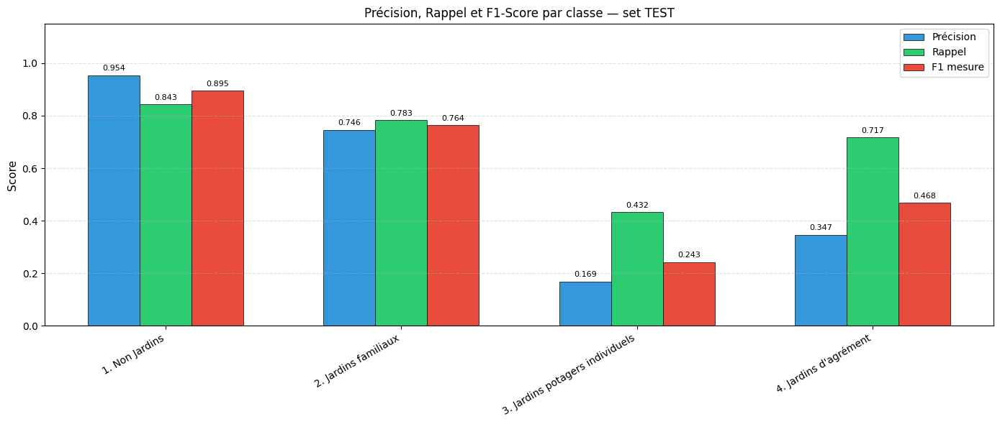

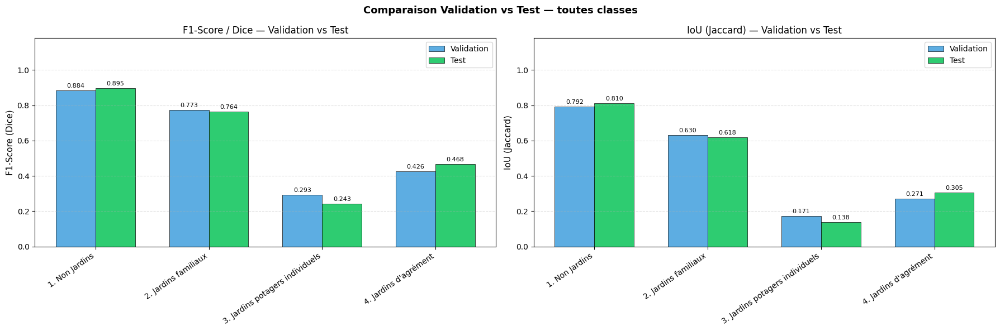

Figures sauvegardées.


In [ ]:
# ── Barres groupées Précision / Rappel / F1 ─────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))
x     = np.arange(N_CLASSES)
width = 0.22
tick_labels = [f'{i+1}. {CLASSES[i]}' for i in range(N_CLASSES)]

b1 = ax.bar(x - width, metrics_test['precision'], width,
            label='Précision', color='#3498DB', edgecolor='black', linewidth=0.5)
b2 = ax.bar(x,          metrics_test['recall'],   width,
            label='Rappel',    color='#2ECC71', edgecolor='black', linewidth=0.5)
b3 = ax.bar(x + width,  metrics_test['dice'],     width,
            label='F1 mesure', color='#E74C3C', edgecolor='black', linewidth=0.5)

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.012,
                f'{h:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(tick_labels, rotation=30, ha='right', fontsize=10)
ax.set_ylabel('Score', fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_title('Précision, Rappel et F1-Score par classe — set TEST', fontsize=12)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('precision_recall_f1_test.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Comparaison Validation vs Test ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
x     = np.arange(N_CLASSES)
width = 0.35
for ax, (val_vals, test_vals, ylabel, title_suffix) in zip(
    axes,
    [(metrics_val['dice'], metrics_test['dice'],
      'F1-Score (Dice)', 'F1-Score / Dice'),
     (metrics_val['iou'],  metrics_test['iou'],
      'IoU (Jaccard)', 'IoU (Jaccard)')]
):
    r1 = ax.bar(x - width/2, val_vals,  width, label='Validation',
                color='#5DADE2', edgecolor='black', linewidth=0.5)
    r2 = ax.bar(x + width/2, test_vals, width, label='Test',
                color='#2ECC71', edgecolor='black', linewidth=0.5)
    for bars in [r1, r2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.01,
                    f'{h:.3f}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(tick_labels, rotation=35, ha='right', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_ylim(0, 1.18)
    ax.set_title(f'{title_suffix} — Validation vs Test', fontsize=12)
    ax.legend(fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Comparaison Validation vs Test — toutes classes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('val_vs_test_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figures sauvegardées.')


## 16. Focus sur les jardins (set TEST)

À partir d'ici, l'analyse est restreinte aux trois classes de jardins : Jardins familiaux, Jardins potagers et Jardins d'agrément. La classe Non Jardins est exclue de tous les calculs qui suivent. La métrique moyenne jardins correspond à la moyenne simple des valeurs obtenues sur ces trois classes uniquement.

### Metriques par classe de jardin -- precision, rappel, F1, IoU



  MÉTRIQUES PAR CLASSE DE JARDIN — set TEST
  Classe                   Précision    Rappel F1 mesure       IoU
  ────────────────────────────────────────────────────────────
  Jardins familiaux           0.7459    0.7833    0.7641    0.6183
  Jardins potagers individuels      0.1692    0.4321    0.2432    0.1384
  Jardins d'agrément          0.3468    0.7173    0.4675    0.3051


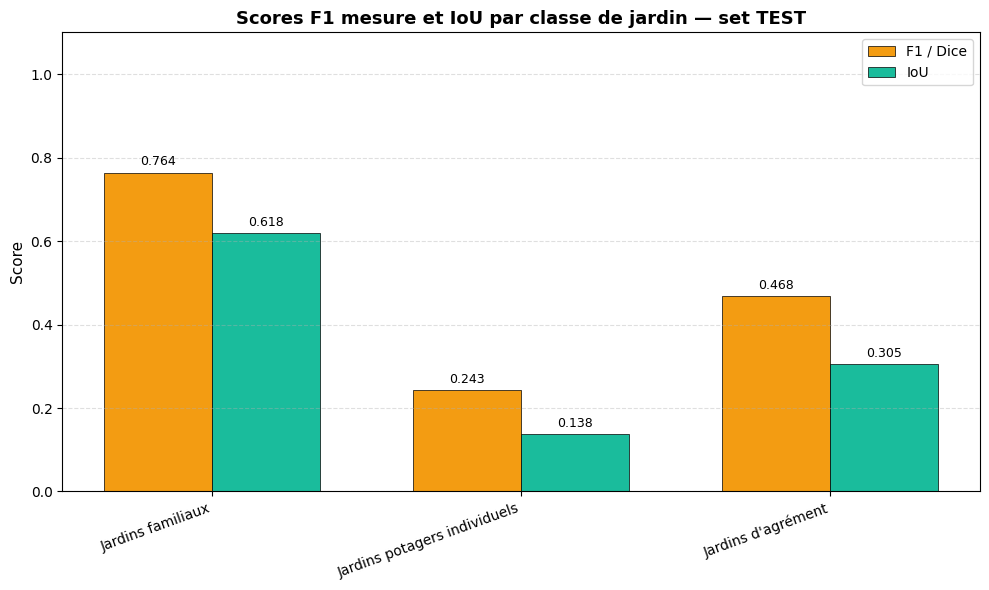

Figure sauvegardée : class_f1_iou_jardins_test.png


In [ ]:
jardins_classes_indices = [1, 2, 3]  # Jardins familiaux, Jardins potagers, Jardins d'agrément
jardins_class_labels = [CLASSES[i] for i in jardins_classes_indices]

jardins_precision = [metrics_test['precision'][i] for i in jardins_classes_indices]
jardins_recall    = [metrics_test['recall'][i]    for i in jardins_classes_indices]
jardins_dice      = [metrics_test['dice'][i]      for i in jardins_classes_indices]
jardins_iou       = [metrics_test['iou'][i]       for i in jardins_classes_indices]

print(f"\n{'='*65}")
print('  MÉTRIQUES PAR CLASSE DE JARDIN — set TEST')
print(f"{'='*65}")
print(f'  {"Classe":<22s} {"Précision":>11s} {"Rappel":>9s} {"F1 mesure":>9s} {"IoU":>9s}')
print('  ' + '─' * 60)
for label, p, r, d, i in zip(jardins_class_labels, jardins_precision, jardins_recall,
                              jardins_dice, jardins_iou):
    print(f'  {label:<22s} {p:>11.4f} {r:>9.4f} {d:>9.4f} {i:>9.4f}')

x = np.arange(len(jardins_class_labels))
width = 0.35

fig_jardins_classes, ax_jardins_classes = plt.subplots(figsize=(10, 6))
rects1 = ax_jardins_classes.bar(x - width/2, jardins_dice, width, label='F1 / Dice',
                                 color='#F39C12', edgecolor='black', linewidth=0.5)
rects2 = ax_jardins_classes.bar(x + width/2, jardins_iou, width, label='IoU',
                                 color='#1ABC9C', edgecolor='black', linewidth=0.5)

ax_jardins_classes.set_ylabel('Score', fontsize=11)
ax_jardins_classes.set_title("Scores F1 mesure et IoU par classe de jardin — set TEST",
                              fontsize=13, fontweight='bold')
ax_jardins_classes.set_xticks(x)
ax_jardins_classes.set_xticklabels(jardins_class_labels, rotation=20, ha='right', fontsize=10)
ax_jardins_classes.set_ylim(0, 1.1)
ax_jardins_classes.legend(fontsize=10)
ax_jardins_classes.grid(axis='y', linestyle='--', alpha=0.4)

def autolabel_jardins(rects):
    for rect in rects:
        height = rect.get_height()
        ax_jardins_classes.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9)

autolabel_jardins(rects1)
autolabel_jardins(rects2)

plt.tight_layout()
plt.savefig('class_f1_iou_jardins_test.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée : class_f1_iou_jardins_test.png')


### Fonction calculate_subset_metrics et metriques moyennes jardins (OA, Kappa)



  MÉTRIQUE MOYENNE JARDINS (3 classes, Non Jardins exclu) — set TEST
  OA (jardins)       : 0.9058
  Kappa (jardins)    : 0.8126
  Précision moyenne  : 0.4206
  Rappel moyen       : 0.6442
  F1 mesure moyen    : 0.4916
  IoU moyen          : 0.3539


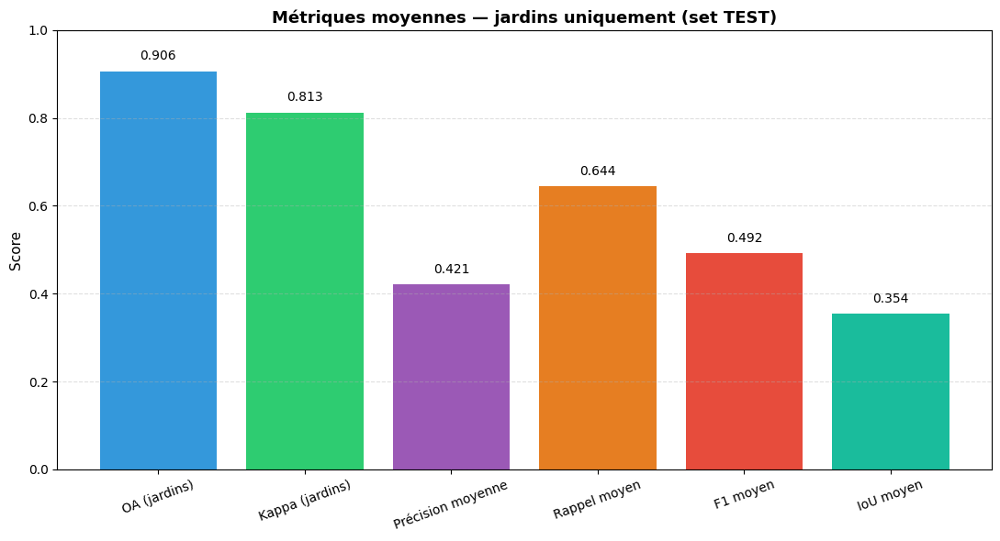

Figure sauvegardée : jardins_mean_metrics_test.png


In [ ]:
def calculate_subset_metrics(cm_raw, subset_indices):
    """
    Calcule l'Overall Accuracy et le Kappa pour un sous-ensemble de classes
    à partir de la matrice de confusion complète.
    """
    cm_subset = cm_raw[np.ix_(subset_indices, subset_indices)]

    total_correct_subset = np.diag(cm_subset).sum()
    total_pixels_subset  = cm_subset.sum()
    oa_subset = float(total_correct_subset) / max(float(total_pixels_subset), 1.0)

    n_total_subset = cm_subset.sum()
    if n_total_subset > 0:
        p_o_subset = np.diag(cm_subset).sum() / n_total_subset
        p_e_subset = ((cm_subset.sum(axis=1) / n_total_subset) *
                      (cm_subset.sum(axis=0) / n_total_subset)).sum()
        kappa_subset = float((p_o_subset - p_e_subset) / (1.0 - p_e_subset + 1e-10))
    else:
        kappa_subset = 0.0

    return oa_subset, kappa_subset


# Moyenne jardins = moyenne simple sur les 3 classes de jardins, Non Jardins exclu
mean_jardins_precision = float(np.mean(jardins_precision))
mean_jardins_recall    = float(np.mean(jardins_recall))
mean_jardins_dice      = float(np.mean(jardins_dice))
mean_jardins_iou       = float(np.mean(jardins_iou))
jardins_oa, jardins_kappa = calculate_subset_metrics(metrics_test['cm_raw'], jardins_classes_indices)

print(f"\n{'='*65}")
print('  MÉTRIQUE MOYENNE JARDINS (3 classes, Non Jardins exclu) — set TEST')
print(f"{'='*65}")
print(f'  OA (jardins)       : {jardins_oa:.4f}')
print(f'  Kappa (jardins)    : {jardins_kappa:.4f}')
print(f'  Précision moyenne  : {mean_jardins_precision:.4f}')
print(f'  Rappel moyen       : {mean_jardins_recall:.4f}')
print(f'  F1 mesure moyen    : {mean_jardins_dice:.4f}')
print(f'  IoU moyen          : {mean_jardins_iou:.4f}')

jardins_metrics_names = [
    'OA (jardins)', 'Kappa (jardins)', 'Précision moyenne',
    'Rappel moyen', 'F1 moyen', 'IoU moyen',
]
jardins_metrics_values = [
    jardins_oa, jardins_kappa, mean_jardins_precision,
    mean_jardins_recall, mean_jardins_dice, mean_jardins_iou,
]

fig_jardins, ax_jardins = plt.subplots(figsize=(11, 6))
bars_jardins = ax_jardins.bar(
    jardins_metrics_names, jardins_metrics_values,
    color=['#3498DB', '#2ECC71', '#9B59B6', '#E67E22', '#E74C3C', '#1ABC9C'])

ax_jardins.set_ylim(0, 1.0)
ax_jardins.set_ylabel('Score', fontsize=11)
ax_jardins.set_title('Métriques moyennes — jardins uniquement (set TEST)',
                      fontsize=13, fontweight='bold')
ax_jardins.tick_params(axis='x', rotation=20, labelsize=10)
ax_jardins.grid(axis='y', linestyle='--', alpha=0.4)

for bar in bars_jardins:
    yval = bar.get_height()
    ax_jardins.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.3f}',
                     ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('jardins_mean_metrics_test.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée : jardins_mean_metrics_test.png')


### Comparaison Validation vs Test -- jardins uniquement (F1 et IoU)


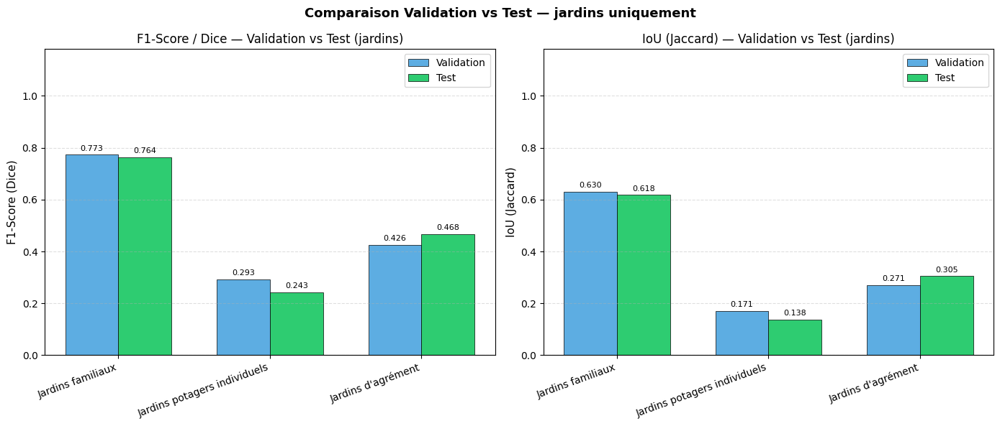

Figure sauvegardée : val_vs_test_metrics_jardins.png


In [ ]:
val_dice_jardins  = [metrics_val['dice'][i]  for i in jardins_classes_indices]
test_dice_jardins = [metrics_test['dice'][i] for i in jardins_classes_indices]
val_iou_jardins   = [metrics_val['iou'][i]   for i in jardins_classes_indices]
test_iou_jardins  = [metrics_test['iou'][i]  for i in jardins_classes_indices]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
x = np.arange(len(jardins_class_labels))
width = 0.35
for ax, (val_vals, test_vals, ylabel, title_suffix) in zip(
    axes,
    [(val_dice_jardins, test_dice_jardins, 'F1-Score (Dice)', 'F1-Score / Dice'),
     (val_iou_jardins,  test_iou_jardins,  'IoU (Jaccard)',   'IoU (Jaccard)')]
):
    r1 = ax.bar(x - width/2, val_vals,  width, label='Validation',
                color='#5DADE2', edgecolor='black', linewidth=0.5)
    r2 = ax.bar(x + width/2, test_vals, width, label='Test',
                color='#2ECC71', edgecolor='black', linewidth=0.5)
    for bars in [r1, r2]:
        for bar in bars:
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.01, f'{h:.3f}',
                    ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(jardins_class_labels, rotation=20, ha='right', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_ylim(0, 1.18)
    ax.set_title(f'{title_suffix} — Validation vs Test (jardins)', fontsize=12)
    ax.legend(fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Comparaison Validation vs Test — jardins uniquement', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('val_vs_test_metrics_jardins.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée : val_vs_test_metrics_jardins.png')


### Courbes ROC one-vs-rest -- jardins uniquement


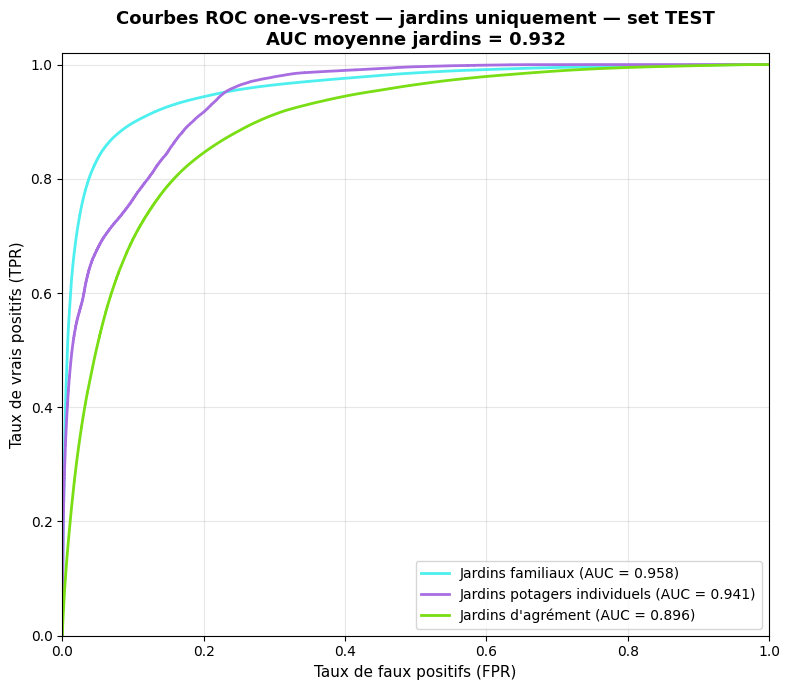

AUC moyenne jardins (3 classes, Non Jardins exclu) = 0.932
Figure sauvegardée : roc_curves_test_jardins.png


In [ ]:
roc_jardins = {c: roc_test[c] for c in jardins_classes_indices if c in roc_test}
aucs_jardins = [a for (_, _, a) in roc_jardins.values()]
mean_auc_jardins = float(np.mean(aucs_jardins)) if aucs_jardins else 0.0

plt.figure(figsize=(8, 7))
for c, (fpr, tpr, a) in sorted(roc_jardins.items()):
    plt.plot(fpr, tpr, color=COLORS[c] if c < len(COLORS) else None, linewidth=2,
             label=f'{CLASSES[c]} (AUC = {a:.3f})')

plt.xlabel('Taux de faux positifs (FPR)', fontsize=11)
plt.ylabel('Taux de vrais positifs (TPR)', fontsize=11)
plt.title(f'Courbes ROC one-vs-rest — jardins uniquement — set TEST\n'
          f'AUC moyenne jardins = {mean_auc_jardins:.3f}',
          fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.tight_layout()
plt.savefig('roc_curves_test_jardins.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'AUC moyenne jardins (3 classes, Non Jardins exclu) = {mean_auc_jardins:.3f}')
print('Figure sauvegardée : roc_curves_test_jardins.png')


## 17. Visualisation des prédictions sur le set TEST

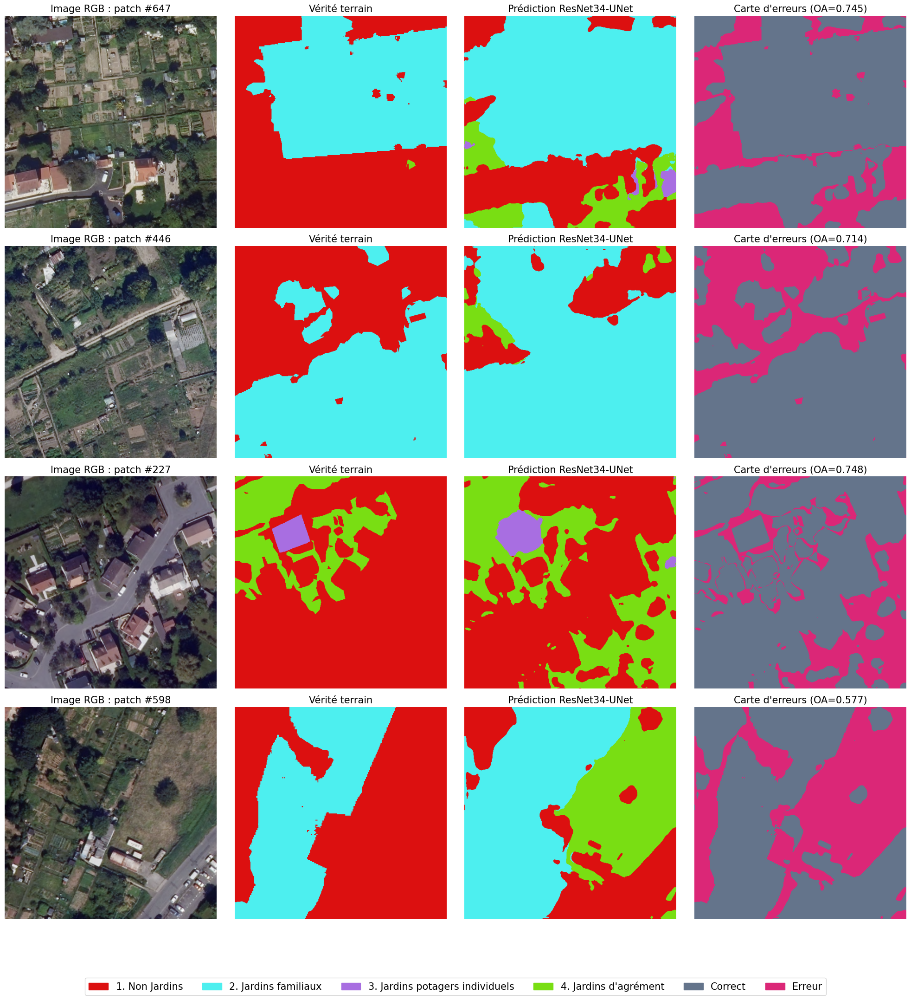

Figure sauvegardée → predictions_test.tiff


34258

In [ ]:
FIXED_IDXS = [647, 446, 227, 598]  # None pour un tirage aléatoire

if FIXED_IDXS is not None:
    idxs = [i for i in FIXED_IDXS if i < len(X_test)]
    if len(idxs) < len(FIXED_IDXS):
        print(f"Attention : certains indices dépassent len(X_test)={len(X_test)}, ignorés.")
else:
    N_VIZ = min(4, len(X_test))
    idxs = random.sample(range(len(X_test)), N_VIZ)

N_VIZ = len(idxs)

# Chargement patch par patch pour économiser la RAM
imgs_list  = [np.array(X_test[i], dtype=np.float32) for i in idxs]
true_list  = [np.array(y_test[i], dtype=np.int64)   for i in idxs]
imgs_t     = torch.from_numpy(np.stack(imgs_list).transpose(0, 3, 1, 2)).to(DEVICE)

model.eval()
with torch.no_grad():
    pred_msk = model(imgs_t).argmax(dim=1).cpu().numpy()
del imgs_t

imgs_np  = np.stack(imgs_list)
true_msk = np.stack(true_list)

fig, axes = plt.subplots(N_VIZ, 4, figsize=(20, N_VIZ * 5))
if N_VIZ == 1:
    axes = axes[np.newaxis, :]

for k in range(N_VIZ):
    axes[k, 0].imshow(np.clip(imgs_np[k, :, :, :3], 0, 1))
    axes[k, 0].set_title(f'Image RGB : patch #{idxs[k]}', fontsize=15)
    axes[k, 0].axis('off')

    axes[k, 1].imshow(mask_to_rgb(true_msk[k]))
    axes[k, 1].set_title('Vérité terrain', fontsize=15)
    axes[k, 1].axis('off')

    axes[k, 2].imshow(mask_to_rgb(pred_msk[k]))
    axes[k, 2].set_title('Prédiction ResNet34-UNet', fontsize=15)
    axes[k, 2].axis('off')

    correct = (pred_msk[k] == true_msk[k]).astype(np.uint8)
    valid   = true_msk[k] != IGNORE_INDEX
    err_map = np.zeros((*true_msk[k].shape, 3), dtype=np.uint8)
    err_map[valid & (correct == 1)] = [100, 116, 139]  # Gris-bleu : Correct
    err_map[valid & (correct == 0)] = [219, 39, 119]  # Magenta vif : Erreur

    axes[k, 3].imshow(err_map)
    acc_k = correct[valid].mean() if valid.any() else 0.0
    axes[k, 3].set_title(f"Carte d'erreurs (OA={acc_k:.3f})", fontsize=15)
    axes[k, 3].axis('off')

legend_patches = [mpatches.Patch(color=COLORS[c], label=f'{c+1}. {CLASSES[c]}')
                  for c in range(N_CLASSES)]
legend_patches += [
    mpatches.Patch(color="#64748B", label="Correct"),
    mpatches.Patch(color="#DB2777", label="Erreur"),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=6, fontsize=15,
           bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()
plt.savefig('/content/predictions_test.tiff', dpi=500, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → predictions_test.tiff')
del imgs_np, true_msk, pred_msk, imgs_list, true_list
gc.collect()

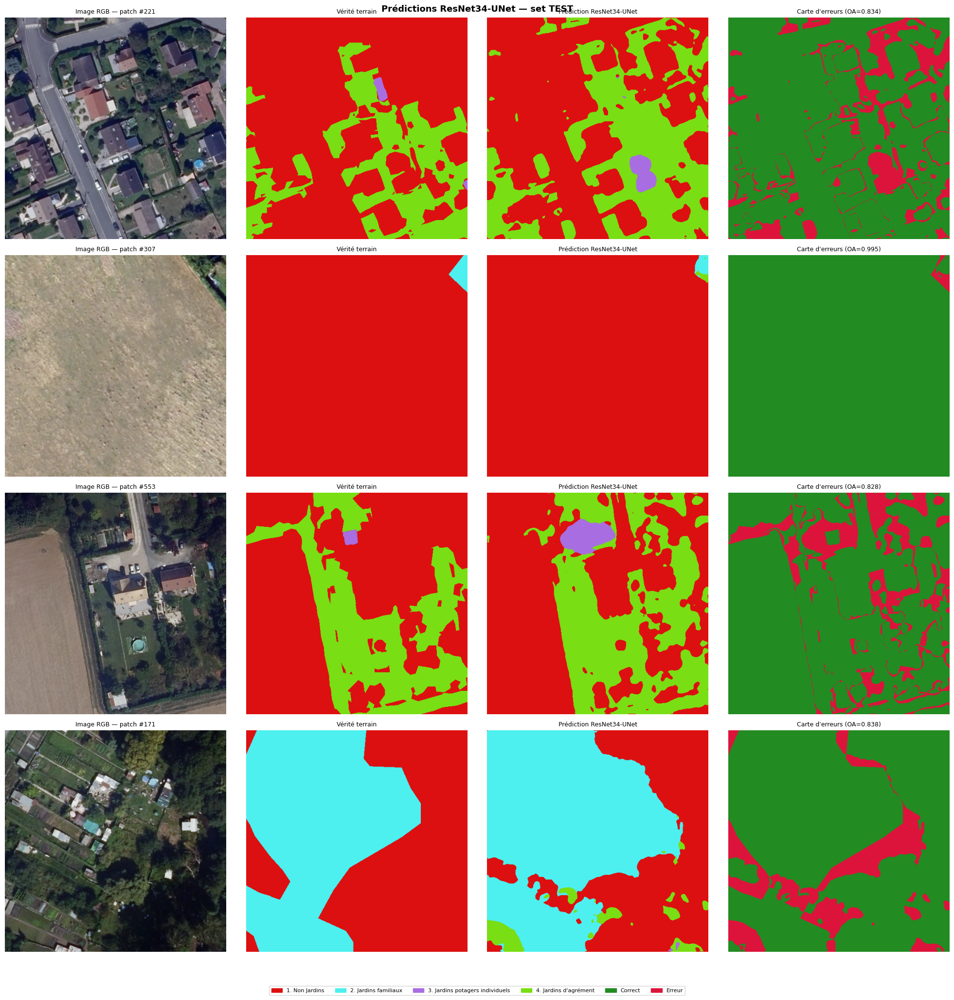

Figure sauvegardée → predictions_test.png


34251

In [ ]:
N_VIZ = min(4, len(X_test))
idxs  = random.sample(range(len(X_test)), N_VIZ)

# Chargement patch par patch pour économiser la RAM
imgs_list  = [np.array(X_test[i], dtype=np.float32) for i in idxs]
true_list  = [np.array(y_test[i], dtype=np.int64)   for i in idxs]
imgs_t     = torch.from_numpy(np.stack(imgs_list).transpose(0, 3, 1, 2)).to(DEVICE)

model.eval()
with torch.no_grad():
    pred_msk = model(imgs_t).argmax(dim=1).cpu().numpy()
del imgs_t

imgs_np  = np.stack(imgs_list)
true_msk = np.stack(true_list)

fig, axes = plt.subplots(N_VIZ, 4, figsize=(20, N_VIZ * 5))
if N_VIZ == 1:
    axes = axes[np.newaxis, :]

for k in range(N_VIZ):
    axes[k, 0].imshow(np.clip(imgs_np[k, :, :, :3], 0, 1))
    axes[k, 0].set_title(f'Image RGB — patch #{idxs[k]}', fontsize=9)
    axes[k, 0].axis('off')

    axes[k, 1].imshow(mask_to_rgb(true_msk[k]))
    axes[k, 1].set_title('Vérité terrain', fontsize=9)
    axes[k, 1].axis('off')

    axes[k, 2].imshow(mask_to_rgb(pred_msk[k]))
    axes[k, 2].set_title('Prédiction ResNet34-UNet', fontsize=9)
    axes[k, 2].axis('off')

    correct = (pred_msk[k] == true_msk[k]).astype(np.uint8)
    valid   = true_msk[k] != IGNORE_INDEX
    err_map = np.zeros((*true_msk[k].shape, 3), dtype=np.uint8)
    err_map[valid & (correct == 1)] = [34, 139, 34]
    err_map[valid & (correct == 0)] = [220,  20, 60]
    axes[k, 3].imshow(err_map)
    acc_k = correct[valid].mean() if valid.any() else 0.0
    axes[k, 3].set_title(f"Carte d'erreurs (OA={acc_k:.3f})", fontsize=9)
    axes[k, 3].axis('off')

legend_patches = [mpatches.Patch(color=COLORS[c], label=f'{c+1}. {CLASSES[c]}')
                  for c in range(N_CLASSES)]
legend_patches += [
    mpatches.Patch(color='#238B22', label='Correct'),
    mpatches.Patch(color='#DC153C', label='Erreur'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=6, fontsize=8,
           bbox_to_anchor=(0.5, -0.04))

plt.suptitle('Prédictions ResNet34-UNet — set TEST', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('predictions_test.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure sauvegardée → predictions_test.png')
del imgs_np, true_msk, pred_msk, imgs_list, true_list
gc.collect()


## 18. Sauvegarde du modèle

### Affichage du resume de l'architecture du modele


In [ ]:
print(model)

ResNet34UNet(
  (encoder_stem): Sequential(
    (0): Conv2d(6, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (encoder_pool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (encoder_layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_runni

### Sauvegarde du modele entraine sur le Drive


In [ ]:
SAVE_PATH = '/content/drive/MyDrive/DATA/jardins_resnet34unet_6bandes_Final.pth'

torch.save({
    'model_state_dict'  : model.state_dict(),
    'n_classes'         : N_CLASSES,
    'in_channels'       : IMAGE_CHANNELS,   # = 6
    'classes'           : CLASSES,
    'colors'            : COLORS,
    'channels'          : CHANNELS,          # = [0,1,2,3,4,5] toutes les bandes
    'patch_size'        : IMAGE_PATCH_SIZE,
    'ignore_index'      : IGNORE_INDEX,
    'history_aug'       : history_aug,
    'history_no_aug'    : history_no_aug,
    # Métriques TEST
    'test_oa'           : float(metrics_test['oa']),
    'test_kappa'        : float(metrics_test['kappa']),
    'test_miou'         : float(metrics_test['miou']),
    'test_dice'         : float(metrics_test['mean_dice']),
    'test_iou_per_cls'  : metrics_test['iou'],
    'test_f1_per_cls'   : metrics_test['dice'],
    # Métriques VALIDATION
    'val_oa'            : float(metrics_val['oa']),
    'val_kappa'         : float(metrics_val['kappa']),
    'val_miou'          : float(metrics_val['miou']),
    # Métriques jardins uniquement (moyenne sur les 3 classes, Non Jardins exclu)
    'test_oa_jardins'        : float(jardins_oa),
    'test_kappa_jardins'     : float(jardins_kappa),
    'test_precision_jardins' : float(mean_jardins_precision),
    'test_recall_jardins'    : float(mean_jardins_recall),
    'test_dice_jardins'      : float(mean_jardins_dice),
    'test_iou_jardins'       : float(mean_jardins_iou),
    # Architecture
    'architecture'      : 'ResNet34-UNet',
    'bandes_entree'     : '6 canaux : R, G, B, NIR, NDVI, MSAVI2 (toutes lues directement)',
    'loss'              : f'FocalDiceLoss(focal={FOCAL_WEIGHT}, dice={DICE_WEIGHT}, gamma={FOCAL_GAMMA})',
    'optimizer'         : f'AdamW(lr_enc={LR_ENCODER}, lr_dec={LR_DECODER}, wd={WEIGHT_DECAY})',
    'scheduler'         : 'OneCycleLR(pct_start=0.1, anneal_strategy=cos)',
    'configuration'     : [
        '6 bandes : R,G,B,NIR, NDVI, MSAVI2 (toutes lues directement)',
        'CHANNELS = [0,1,2,3,4,5] — 6 bandes lues depuis .tif',
        "Aucun calcul d'indice spectral : NDVI et MSAVI2 sont déjà présents dans les bandes sources",
        'NUM_BANDS = 6 (entrée modèle)',
        'AdamW + LR différencié encodeur/décodeur',
        'OneCycleLR (warmup cosine)',
        'Dropout renforcé (0.4/0.3/0.2/0.1/0.1)',
        f'Label Smoothing = {LABEL_SMOOTHING}',
        f'FocalDiceLoss (focal={FOCAL_WEIGHT}, dice={DICE_WEIGHT}, gamma={FOCAL_GAMMA})',
        'WeightedRandomSampler (potagers x3)',
        'Normalisation percentile [2,98] cohérente train/inférence',
    ],
}, SAVE_PATH)
print(f'Modèle  sauvegardé → {SAVE_PATH}')
print(f'  Canaux entrée : {IMAGE_CHANNELS} (R, G, B, NIR, NDVI, MSAVI2)')

Modèle  sauvegardé → /content/drive/MyDrive/DATA/jardins_resnet34unet_6bandes_Final.pth
  Canaux entrée : 6 (R, G, B, NIR, NDVI, MSAVI2)


### Visualisation de l'architecture du modèle (image)

### Generation du graphe d'architecture avec torchviz


In [ ]:
import torch
import torch.nn as nn
!pip install -q graphviz torchviz
from torchviz import make_dot

# Assuming 'model' is already loaded and on the correct device (CPU or GPU)
# Create a dummy input tensor with the expected shape (batch_size, num_bands, patch_size, patch_size)
dummy_input = torch.randn(1, NUM_BANDS, IMAGE_PATCH_SIZE, IMAGE_PATCH_SIZE).to(DEVICE)

# Generate the computation graph using torchviz
dot = make_dot(model(dummy_input), params=dict(model.named_parameters()))

# Render the graph to a file (e.g., PNG)
dot.render("model_architecture", format="png", cleanup=True)
print("Architecture du modèle sauvegardée sous forme d'image : model_architecture.png")


Architecture du modèle sauvegardée sous forme d'image : model_architecture.png


### Affichage de l'image du graphe d'architecture


In [ ]:
from IPython.display import Image
Image('model_architecture.png')

### Visualisation du modèle

![Model Architecture](model_architecture.png)

## 19. Inférence grande image — Tuilage + Soft-Voting + Hann

Configuration des chemins et paramètres d'inférence.


### Chemins et parametres d'inference (a adapter)


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# CHEMINS INFÉRENCE — À MODIFIER
# ════════════════════════════════════════════════════════════════════════════
MODEL_PATH = '/content/drive/MyDrive/DATA/jardins_resnet34unet_6bandes_Final.pth'
JP2_FOLDER = '/content/drive/MyDrive/DATA'
OUTPUT_DIR = '/content/drive/MyDrive/predictions_batch/'

# ════════════════════════════════════════════════════════════════════════════
# PARAMÈTRES INFÉRENCE
# ════════════════════════════════════════════════════════════════════════════
BATCH_GPU = 8       # tuiles 512x512 par batch GPU (a augmenter si la RAM GPU le permet)
BLOCK_SIZE = 4096    # taille des blocs de lecture rasterio (pixels)
OVERLAP_PX = 256        # marge de chevauchement (pixels), doit etre paire
NORM_MODE = 'minmax' # 'percentile' (recommande pour JP2) ou 'minmax'

PATCH_SIZE_INFER = IMAGE_PATCH_SIZE
OVERLAP_RATIO = 0.5                                              # 50% de recouvrement pour un meilleur lissage
MARGIN_INFER = int(PATCH_SIZE_INFER * OVERLAP_RATIO / 2)         # marge de chaque cote
STEP_INFER = PATCH_SIZE_INFER - 2 * MARGIN_INFER                 # pas d'extraction des patches
CHANNELS_INFERENCE = CHANNELS
BATCH_INFER = 2      # reduit pour limiter la consommation de RAM GPU

print(f'Overlap        : {OVERLAP_RATIO * 100:.0f}% (marge={MARGIN_INFER}px, pas={STEP_INFER}px)')
print(f'Batch GPU      : {BATCH_INFER}')
print(f'Normalisation  : {NORM_MODE}')
NORM_MODE    = 'minmax'
USE_FP16_ACC = True
USE_MMAP     = True
MMAP_PATH    = '/content/tmp_logits_acc'

# Bandes lues directement depuis les .jp2 (R, G, B, NIR, NDVI, MSAVI2)
INFER_CHANNELS = [0, 1, 2, 3, 4, 5]

print('='*55)
print('  CONFIGURATION INFÉRENCE')
print('='*55)
print(f'  Modèle         : {MODEL_PATH}')
print(f'  Patch size     : {IMAGE_PATCH_SIZE}px')
print(f'  Overlap        : {OVERLAP_PX}px ({100*OVERLAP_PX/IMAGE_PATCH_SIZE:.0f}%)')
print(f'  Step           : {STEP_INFER}px')
print(f'  Bandes lues    : {INFER_CHANNELS}  (R, G, B, NIR, NDVI, MSAVI2)')
print(f'  Canaux modèle  : {NUM_BANDS}  (toutes lues directement)')
print(f'  FP16 acc       : {USE_FP16_ACC}')
print(f'  MMAP disque    : {USE_MMAP}')

Overlap        : 50% (marge=128px, pas=256px)
Batch GPU      : 2
Normalisation  : minmax
  CONFIGURATION INFÉRENCE
  Modèle         : /content/drive/MyDrive/DATA/jardins_resnet34unet_6bandes_Final.pth
  Patch size     : 512px
  Overlap        : 256px (50%)
  Step           : 256px
  Bandes lues    : [0, 1, 2, 3, 4, 5]  (R, G, B, NIR, NDVI, MSAVI2)
  Canaux modèle  : 6  (toutes lues directement)
  FP16 acc       : True
  MMAP disque    : True


### Fonction normaliser_patch_6bandes


In [ ]:
def normalize_image(arr, mode='minmax'):
    """Normalisation canal par canal.

    Args:
        arr (np.ndarray): image sous forme de tableau numpy (H, W, C).
        mode (str): 'minmax' (seul mode pris en charge ici).

    Returns:
        np.ndarray: image normalisee dans l'intervalle [0, 1].
    """
    arr = arr.astype(np.float32)
    if mode == 'minmax':
        for c in range(arr.shape[2]):
            band = arr[:, :, c]
            mn, mx = band.min(), band.max()
            arr[:, :, c] = (band - mn) / (mx - mn + 1e-8) if mx > mn else np.zeros_like(band)
    else:
        raise ValueError(f"Mode de normalisation inconnu : {mode}. Choisissez 'minmax' ou 'percentile'.")
    return arr

### Import de la barre de progression pour l'inference


In [ ]:
# ── Fonctions inférence ──────────────────────────────────────────────────────
from tqdm.notebook import tqdm


### Fonction hann_window_2d -- fenetre de ponderation pour le soft-voting


In [ ]:
def make_hann_window(patch_size):
    """Genere une fenetre de ponderation Hann 2D de taille (patch_size, patch_size).

    Les bords du patch ont un poids proche de 0 et le centre un poids proche
    de 1. Cette fenetre permet d'eliminer les artefacts de tuilage en
    lissant les jonctions entre patches lors de l'accumulation des logits.
    """
    hann_1d = np.hanning(patch_size).astype(np.float32)
    window = np.outer(hann_1d, hann_1d)          # produit tensoriel 2D
    window = window / (window.max() + 1e-8)      # normalisation a 1
    return window


In [ ]:
def apply_post_processing(mask, min_size=50, connectivity=1):
    """Applique un post-traitement pour supprimer les petits objets isoles.

    Args:
        mask (np.ndarray): masque de segmentation predit.
        min_size (int): taille minimale des objets a conserver, en pixels.
        connectivity (int): connectivite pour la detection des objets
            (1 pour 4-connecte, 2 pour 8-connecte).

    Returns:
        np.ndarray: masque nettoye.
    """
    processed_mask = np.copy(mask)
    for class_id in np.unique(mask):
        if class_id == IGNORE_INDEX or class_id < 0:
            continue
        binary_class_mask = (mask == class_id)
        cleaned_binary_mask = remove_small_objects(binary_class_mask, min_size=min_size, connectivity=connectivity)
        processed_mask[binary_class_mask & ~cleaned_binary_mask] = 0   # reaffecte a 'Non jardins'
    return processed_mask

In [ ]:
def clean_linear_structures(binary_mask, min_size=50, block=4096, pad=16):
    """Supprime les petits objets et les structures fines ou lineaires (comme
    les routes), en traitant l'image par tuiles afin de limiter la RAM.

    Args:
        binary_mask (np.ndarray[bool]): masque binaire de la classe a nettoyer.
        min_size (int): taille minimale des objets conserves.
        block (int): taille des tuiles de traitement, en pixels.
        pad (int): marge de recouvrement entre tuiles pour eviter les
            artefacts de bord de la morphologie (doit etre superieure ou
            egale au rayon du disque structurant).

    Returns:
        np.ndarray[uint8]: masque nettoye, de meme forme que l'entree.
    """
    H, W = binary_mask.shape
    out = np.zeros((H, W), dtype=np.uint8)
    selem = morphology.disk(3)

    for row in range(0, H, block):
        for col in range(0, W, block):
            r0, r1 = row, min(row + block, H)
            c0, c1 = col, min(col + block, W)

            # Fenetre elargie (avec marge) pour que l'ouverture morphologique
            # ne soit pas biaisee aux bords de la tuile
            pr0, pr1 = max(0, r0 - pad), min(H, r1 + pad)
            pc0, pc1 = max(0, c0 - pad), min(W, c1 + pad)

            tile = binary_mask[pr0:pr1, pc0:pc1]
            if not tile.any():
                continue   # tuile vide : rien a nettoyer

            opened = morphology.binary_opening(tile, selem)
            opened = morphology.remove_small_objects(opened, min_size=min_size)

            # Recadrage de la marge pour ne garder que la zone utile de la tuile
            oi0, oi1 = r0 - pr0, r0 - pr0 + (r1 - r0)
            oj0, oj1 = c0 - pc0, c0 - pc0 + (c1 - c0)
            out[r0:r1, c0:c1] = opened[oi0:oi1, oj0:oj1].astype(np.uint8)

            del tile, opened

    return out

### Fonction predict_large_image -- inference par tuilage avec soft-voting et fenetre de Hann


In [ ]:
def predict_large_image_gpu_batch(
    image_path, model, channels, patch_size,
    n_classes, device, block_size=4096, overlap=64,
    batch_gpu=8, norm_mode='percentile'
):
    """Inference par blocs avec batching GPU et accumulation de logits ponderes (Hann).

    Principe :
    - Soft-voting : accumulation des logits multiplies par la fenetre de Hann
      dans `logits_acc`.
    - `weight_acc` accumule les poids correspondants pour la normalisation
      finale.
    - L'argmax est applique sur les logits accumules et normalises, ce qui
      produit des transitions douces aux jonctions entre patches.
    - Le masque de sortie est stocke en uint8 (plutot qu'en int32) et
      `logits_acc` respecte le mode float16 si celui-ci est active
      globalement, afin de limiter la consommation de RAM.

    Returns:
        tuple: (class_counts, preview_rgb, transform_geo, crs_geo, predicted_mask_array)
    """
    model.eval()
    inner_step = patch_size - overlap   # pas entre tuiles (ex. 512-64=448)

    # Respecte le mode defini dans la cellule de configuration (RAM /2 sur l'accumulateur)
    acc_dtype = np.float16 if globals().get('USE_FP16_ACC', False) else np.float32

    # Fenetre de Hann calculee une seule fois pour tous les patches
    hann_win = make_hann_window(patch_size)

    with rasterio.open(image_path) as src:
        H_total, W_total = src.height, src.width
        n_bands = src.count
        transform_geo = src.transform
        crs_geo = src.crs
        band_indices = [c + 1 for c in channels if c < n_bands]

    # uint8 : suffisant tant que n_classes <= 255 (RAM /4 par rapport a int32)
    predicted_mask_array = np.zeros((H_total, W_total), dtype=np.uint8)

    n_blocks_h = math.ceil(H_total / block_size)
    n_blocks_w = math.ceil(W_total / block_size)
    total_blocks = n_blocks_h * n_blocks_w
    class_counts = np.zeros(n_classes, dtype=np.int64)
    preview_rgb = None

    # Marge de lecture elargie pour les chevauchements inter-blocs
    margin = overlap // 2

    with tqdm(total=total_blocks, desc='  |_ Blocs', leave=False) as pbar:
        for bi in range(n_blocks_h):
            for bj in range(n_blocks_w):
                row_off = bi * block_size
                col_off = bj * block_size
                bh_base = min(block_size, H_total - row_off)
                bw_base = min(block_size, W_total - col_off)

                # Lecture avec marge de chevauchement inter-blocs
                read_col = max(0, col_off - margin)
                read_row = max(0, row_off - margin)
                read_w = min(W_total - read_col, bw_base + 2 * margin)
                read_h = min(H_total - read_row, bh_base + 2 * margin)
                read_win = Window(read_col, read_row, read_w, read_h)

                with rasterio.open(image_path) as src:
                    data = src.read(band_indices, window=read_win)

                # Padding des bandes manquantes
                if data.shape[0] < len(channels):
                    pad_arr = np.zeros((len(channels), data.shape[1], data.shape[2]), dtype=data.dtype)
                    pad_arr[:data.shape[0]] = data
                    data = pad_arr

                # Normalisation
                block = normalize_image(data.transpose(1, 2, 0).astype(np.float32), mode=norm_mode)
                del data

                if preview_rgb is None:
                    preview_rgb = block[:512, :512, :3].copy()

                # Padding du bloc pour obtenir une grille de tuiles complete
                H_b, W_b = block.shape[:2]
                H_pad = math.ceil((H_b - overlap) / inner_step) * inner_step + patch_size
                W_pad = math.ceil((W_b - overlap) / inner_step) * inner_step + patch_size
                if H_pad < H_b:
                    H_pad = H_b + inner_step
                if W_pad < W_b:
                    W_pad = W_b + inner_step
                block = np.pad(block,
                               ((0, H_pad - H_b), (0, W_pad - W_b), (0, 0)),
                               mode='reflect')

                # Accumulateurs pour le soft-voting (logits ponderes Hann)
                logits_acc = np.zeros((n_classes, H_pad, W_pad), dtype=acc_dtype)
                weight_acc = np.zeros((H_pad, W_pad), dtype=np.float32)

                # Collecte des patches
                patches_list, coords_list = [], []
                for i in range(0, H_pad - patch_size + 1, inner_step):
                    for j in range(0, W_pad - patch_size + 1, inner_step):
                        patch = block[i:i+patch_size, j:j+patch_size, :]
                        patches_list.append(torch.from_numpy(patch.transpose(2, 0, 1)))
                        coords_list.append((i, j))

                # Inference par batch GPU
                with torch.no_grad():
                    for start in range(0, len(patches_list), batch_gpu):
                        batch = torch.stack(
                            patches_list[start:start + batch_gpu]
                        ).to(device, non_blocking=True)

                        # Logits bruts avant argmax, de forme (B, C, H, W)
                        logits_batch = model(batch).cpu().numpy()

                        for k, (i, j) in enumerate(coords_list[start:start + batch_gpu]):
                            logits = logits_batch[k]
                            # Accumulation ponderee : logits x fenetre de Hann
                            logits_acc[:, i:i+patch_size, j:j+patch_size] += \
                                (logits * hann_win[np.newaxis]).astype(acc_dtype)
                            weight_acc[i:i+patch_size, j:j+patch_size] += hann_win

                        del batch, logits_batch
                        if device.type == 'cuda':
                            torch.cuda.empty_cache()

                del patches_list, block

                # Normalisation puis argmax
                w_safe = np.maximum(weight_acc, 1e-8)[np.newaxis]
                pred_block = (logits_acc.astype(np.float32) / w_safe).argmax(axis=0).astype(np.uint8)

                del logits_acc, weight_acc

                # Recadrage au bloc utile (retire la marge de lecture inter-blocs)
                crop_i = row_off - read_row
                crop_j = col_off - read_col
                final_block = pred_block[crop_i: crop_i + bh_base,
                                         crop_j: crop_j + bw_base]

                predicted_mask_array[row_off: row_off + bh_base, col_off: col_off + bw_base] = final_block

                for c in range(n_classes):
                    class_counts[c] += (final_block == c).sum()

                del pred_block, final_block
                gc.collect()
                pbar.update(1)

    return class_counts, preview_rgb, transform_geo, crs_geo, predicted_mask_array

### Confirmation de la definition de predict_large_image


### Execution de l'inference sur l'ensemble des images .jp2 du dossier


In [ ]:
def executer_prediction_batch(jp2_files, model, output_dir):
    """
    Applique l'inférence et enregistre uniquement le résultat brut (0-indexed).
    """
    global_report = []

    for i, img_path in enumerate(tqdm(jp2_files, desc='Progression globale')):
        basename = os.path.splitext(os.path.basename(img_path))[0]
        out_tif = os.path.join(output_dir, f'{basename}_pred_raw.tif')

        print(f'\n[{i+1}/{len(jp2_files)}] Traitement : {os.path.basename(img_path)}')

        # 1. Inférence
        class_counts, preview_rgb, transform_geo, crs_geo, pred_data = predict_large_image_gpu_batch(
            image_path=img_path,
            model=model,
            channels=CHANNELS,
            patch_size=IMAGE_PATCH_SIZE,
            n_classes=N_CLASSES,
            device=DEVICE,
            block_size=BLOCK_SIZE,
            overlap=OVERLAP,
            batch_gpu=BATCH_GPU,
            norm_mode=NORM_MODE,
        )

        # 2. Écriture du masque brut (0-indexed)
        tmp_profile = {
            'driver': 'GTiff',
            'height': pred_data.shape[0],
            'width': pred_data.shape[1],
            'count': 1,
            'dtype': rasterio.uint8,
            'crs': crs_geo,
            'transform': transform_geo,
            'compress': 'lzw',
            'nodata': None
        }
        with rasterio.open(out_tif, 'w', **tmp_profile) as dst:
            dst.write(pred_data, 1)

        # 3. Calcul des statistiques sur le résultat brut
        row = {'fichier': os.path.basename(img_path)}
        total_px = pred_data.size

        for c in range(N_CLASSES):
            cnt = int(np.sum(pred_data == c))
            pct = 100 * cnt / total_px if total_px > 0 else 0
            row[CLASSES[c]] = round(pct, 2)
            if cnt > 0:
                print(f'    [{c+1:2d}] {CLASSES[c]:<25s} {cnt:>10,} px  ({pct:.1f}%)')

        global_report.append(row)

        # 4. Libération mémoire
        del pred_data, preview_rgb
        gc.collect()
        if DEVICE.type == 'cuda': torch.cuda.empty_cache()

    return global_report

In [ ]:
def sauvegarder_rapport_csv(global_report, output_dir):
    """Ecrit le rapport de synthese (distribution des classes par image) au format CSV."""
    print('\n' + '=' * 70)
    print('  RAPPORT BATCH')
    print('=' * 70)
    report_csv = os.path.join(output_dir, 'batch_report_filtered.csv')
    if global_report:
        keys = global_report[0].keys()
        with open(report_csv, 'w', newline='') as f:
            w = csv.DictWriter(f, fieldnames=keys)
            w.writeheader()
            w.writerows(global_report)
        print(f'  Rapport CSV filtre -> {report_csv}')
    print(f'  GeoTIFF filtre     -> {output_dir}')

In [ ]:
def charger_modele(model_path):
    """Charge un checkpoint entraine et retourne le modele pret pour l'inference."""
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

    print(f'Chargement : {model_path}')
    checkpoint = torch.load(model_path, map_location=DEVICE, weights_only=False)

    if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
        state_dict = checkpoint['model_state_dict']
        in_ch = checkpoint.get('in_channels', NUM_BANDS)
        n_cls = checkpoint.get('n_classes', N_CLASSES)
        oa = checkpoint.get('test_oa', 'N/A')
        kappa = checkpoint.get('test_kappa', 'N/A')
        miou = checkpoint.get('test_miou', 'N/A')
        print(f'  OA={oa}  Kappa={kappa}  mIoU={miou}')
    else:
        state_dict = checkpoint
        in_ch, n_cls = NUM_BANDS, N_CLASSES

    model = build_model(num_classes=n_cls, in_channels=in_ch)

    missing_keys, unexpected_keys = model.load_state_dict(state_dict, strict=False)

    if missing_keys or unexpected_keys:
        print('\n[ATTENTION] Le state_dict ne correspond pas exactement a l\'architecture. Chargement partiel effectue.')
        print('Diagnostic complet ci-dessous :\n')

        if missing_keys:
            print(f'--- Cles manquantes dans le checkpoint ({len(missing_keys)}) ---')
            for k in missing_keys:
                print(' ', k, tuple(model.state_dict()[k].shape))

        if unexpected_keys:
            print(f'\n--- Cles inattendues dans le modele ({len(unexpected_keys)}) ---')
            for k in unexpected_keys:
                print(' ', k, tuple(state_dict[k].shape))

        model_keys_set = set(model.state_dict().keys())
        ckpt_keys_set = set(state_dict.keys())
        common_keys_set = model_keys_set.intersection(ckpt_keys_set)

        shape_mismatches_found = False
        for k in sorted(common_keys_set):
            s1, s2 = tuple(model.state_dict()[k].shape), tuple(state_dict[k].shape)
            if s1 != s2:
                if not shape_mismatches_found:
                    print('\n--- Mismatch de forme sur cles communes ---')
                    shape_mismatches_found = True
                print(f'  {k}: modele={s1}  checkpoint={s2}')

    model.eval()
    del checkpoint, state_dict
    gc.collect()

    print('\nModele charge et pret.')
    print_ram()
    return model

In [ ]:
model = charger_modele(MODEL_PATH)

Chargement : /content/drive/MyDrive/DATA/jardins_resnet34unet_6bandes_Final.pth
  OA=0.825407140057786  Kappa=0.5613118861388251  mIoU=0.46798667178374176
  ResNet34-UNet sur cuda
  Paramètres totaux       : 24,540,484
  Paramètres entraînables : 24,540,484

Modele charge et pret.
  RAM système : 4.6 / 13.6 GB (36%)
  GPU         : 0.21 GB allouée / 0.33 GB réservée


In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

jp2_files = sorted(glob.glob(os.path.join(JP2_FOLDER, '*.jp2')))
print(f'Fichiers .jp2 trouves : {len(jp2_files)}')
for f in jp2_files:
    print(f'  {os.path.basename(f)}')

if not jp2_files:
    print("[INFO] Aucun .jp2 trouve. Deposez vos fichiers .jp2 dans JP2_FOLDER.")
else:
    global_report = executer_prediction_batch(jp2_files, model, OUTPUT_DIR)
    sauvegarder_rapport_csv(global_report, OUTPUT_DIR)

Fichiers .jp2 trouves : 1
  60-2024-0705-6920-LA93-0M20-FUSION-6B.jp2


Progression globale:   0%|          | 0/1 [00:00<?, ?it/s]


[1/1] Traitement : 60-2024-0705-6920-LA93-0M20-FUSION-6B.jp2


NameError: name 'OVERLAP' is not defined

## 20. Références

### Architecture
1. **He et al. (2016).** Deep Residual Learning for Image Recognition. *CVPR 2016*. https://arxiv.org/abs/1512.03385
2. **Ronneberger et al. (2015).** U-Net. *MICCAI 2015*. https://arxiv.org/abs/1505.04597

### Fonction de perte
3. **Lin et al. (2017).** Focal Loss for Dense Object Detection. *ICCV 2017*. https://arxiv.org/abs/1708.02002
4. **Szegedy et al. (2016).** Rethinking the Inception Architecture — Label Smoothing. *CVPR 2016*. https://arxiv.org/abs/1512.00567

### Optimiseur et scheduler
5. **Loshchilov & Hutter (2019).** Decoupled Weight Decay Regularization (AdamW). *ICLR 2019*. https://arxiv.org/abs/1711.05101
6. **Smith & Touvron (2019).** Super-Convergence via One-Cycle LR Policy. https://arxiv.org/abs/1708.07120
7. **Kingma & Ba (2015).** Adam. *ICLR 2015*. https://arxiv.org/abs/1412.6980

### Métriques
8. **Cohen (1960).** Kappa coefficient. *Educational and Psychological Measurement*, 20(1).
9. **Everingham et al. (2010).** The PASCAL VOC Challenge. *IJCV*, 88(2), 303–338.

### Indices spectraux
10. **Qi et al. (1994).** MSAVI2. *Remote Sensing of Environment*, 48(2), 119–126.
11. **Rouse et al. (1974).** NDVI. *Third ERTS Symposium*, NASA.

### Dataset et augmentation
12. **Buslaev et al. (2020).** Albumentations. *Information*, 11(2), 125.
13. **Garioud et al. (2022).** FLAIR #1. *IGN / Zenodo*. https://doi.org/10.5281/zenodo.6672485
